# Práctica 4: Ensambles de clasificadores

César Eduardo Jardines Mendoza

Cuatrimestre III-2026

CICESE

### Descripción de la práctica

En la Práctica 3 optimizamos cinco clasificadores (árbol de decisión, Naive Bayes, kNN, SVM y regresión logística) para predecir si un estudiante va a desertar, seguir inscrito o graduarse, usando el dataset *Predict Students' Dropout and Academic Success* de la UCI. En esta práctica queremos responder la siguiente pregunta: ¿cuánto ganan los ensambles sobre esos cinco clasificadores cuando ya están bien ajustados?

Un ensamble es un modelo que combina las predicciones de varios clasificadores para tomar una sola decisión. La idea es que, si cada clasificador se equivoca en estudiantes distintos, al juntarlos los errores se pueden compensar. En esta práctica vamos a revisar tres familias de ensambles:

- ***Bagging*** entrena muchos árboles, cada uno con una muestra distinta de los datos, y promedia sus votos.
- ***Boosting*** entrena árboles uno después de otro, y cada árbol nuevo se enfoca en los estudiantes en los que se equivocaron los anteriores.
- **Votación y *stacking*** combinan clasificadores que ya existen, en este caso los cinco de la Práctica 3.

La práctica tiene dos partes. En la Parte 1 trabajamos con el conjunto de deserción estudiantil, con los mismos atributos, el mismo preprocesamiento y los mismos cinco pliegues de la Práctica 3, para que los resultados se puedan comparar directamente. En la Parte 2 aplicamos lo aprendido al conjunto *Bank Marketing* de la Tarea 4.

# Parte 1. Deserción estudiantil

## 1. Preparación del entorno y de los datos

En esta fase recuperamos todo lo que necesitamos de la Práctica 3: los datos, los atributos que se conocen al cierre del primer semestre, el preprocesamiento y los cinco pliegues. También definimos una función para evaluar todos los modelos de la misma forma.

Importamos las librerías, fijamos la semilla y mostramos las versiones utilizadas. Además de las librerías de la Práctica 3, ahora usamos XGBoost y LightGBM para los modelos de *boosting*.

In [1]:
import sys
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import scipy
import sklearn
import joblib
import xgboost
import lightgbm

SEED = 42
np.random.seed(SEED)

# Avisos que no afectan los resultados (los mismos que en la Práctica 3)
warnings.filterwarnings("ignore", message="'penalty' was deprecated")
warnings.filterwarnings("ignore", message="Inconsistent values")
warnings.filterwarnings("ignore", message="Bins whose width are too small")
warnings.filterwarnings("ignore", message="The current default behavior, quantile_method")
warnings.filterwarnings("ignore", message="X does not have valid feature names")
pd.set_option("display.max_colwidth", None)

print("Python      ", sys.version.split()[0])
print("numpy       ", np.__version__)
print("pandas      ", pd.__version__)
print("scipy       ", scipy.__version__)
print("matplotlib  ", matplotlib.__version__)
print("scikit-learn", sklearn.__version__)
print("xgboost     ", xgboost.__version__)
print("lightgbm    ", lightgbm.__version__)
print("joblib      ", joblib.__version__)

Python       3.13.5
numpy        2.5.4
pandas       3.1.1
scipy        1.18.1
matplotlib   3.11.2
scikit-learn 1.9.1
xgboost      3.4.1
lightgbm     4.7.0
joblib       1.6.0


Cargamos el conjunto de entrenamiento con una ruta relativa y definimos los mismos grupos de atributos que en la Práctica 3. Como en esta práctica no generamos predicciones para el conjunto de prueba, solo lo cargamos para obtener la lista de atributos disponibles al cierre del primer semestre, que son los mismos con los que trabajamos antes.

In [2]:
train = pd.read_csv("desercion-entrenamiento.csv")
test = pd.read_csv("desercion-prueba.csv")

NOMINALES = ["Marital status", "Application mode", "Course", "Previous qualification",
             "Nacionality", "Mother's qualification", "Father's qualification",
             "Mother's occupation", "Father's occupation"]
BINARIAS = ["Daytime/evening attendance", "Displaced", "Educational special needs",
            "Debtor", "Tuition fees up to date", "Gender", "Scholarship holder",
            "International"]

# Atributos disponibles al cierre del primer semestre = los que trae prueba
ATRIBUTOS = [c for c in test.columns if c != "id"]
NUMERICAS = [c for c in ATRIBUTOS if c not in NOMINALES + BINARIAS]

print("Entrenamiento:", train.shape)
print("Atributos:", len(ATRIBUTOS), "| nominales:", len(NOMINALES),
      "| binarios:", len(BINARIAS), "| numéricos:", len(NUMERICAS))

Entrenamiento: (3539, 38)
Atributos: 30 | nominales: 9 | binarios: 8 | numéricos: 13


XGBoost necesita que las clases estén representadas con números, entonces convertimos *Target* a 0 (*Dropout*), 1 (*Enrolled*) y 2 (*Graduate*). Usamos el mismo orden alfabético de las clases, por lo que los pliegues estratificados salen exactamente iguales que en la Práctica 3. Esto lo verificamos comparando los índices de validación de cada pliegue con los que se obtienen usando las etiquetas originales.

In [3]:
from sklearn.model_selection import StratifiedKFold

CLASES = ["Dropout", "Enrolled", "Graduate"]
X = train[ATRIBUTOS]
y = train["Target"].map({clase: i for i, clase in enumerate(CLASES)})

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
FOLDS = list(cv.split(X, y))

# Los pliegues con las etiquetas originales (como en la Práctica 3)
FOLDS_P3 = list(cv.split(X, train["Target"]))
print("¿Mismos pliegues que en la Práctica 3?",
      all(np.array_equal(a[1], b[1]) for a, b in zip(FOLDS, FOLDS_P3)))
print(y.value_counts().sort_index().rename(index=dict(enumerate(CLASES))))

¿Mismos pliegues que en la Práctica 3? True
Target
Dropout     1137
Enrolled     635
Graduate    1767
Name: count, dtype: int64


Definimos el mismo preprocesamiento de la Práctica 3. Los atributos nominales se codifican con one-hot (agrupando las categorías con menos de 10 estudiantes), los binarios se dejan como están y los numéricos se estandarizan solo para los modelos que dependen de la escala.

In [4]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, KBinsDiscretizer
from sklearn.pipeline import Pipeline


def preprocesador(escalar=True):
    return ColumnTransformer([
        ("nominales", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=10), NOMINALES),
        ("binarias", "passthrough", BINARIAS),
        ("numericas", StandardScaler() if escalar else "passthrough", NUMERICAS),
    ])

Para que todos los modelos se evalúen igual, definimos una función que usa `cross_validate` con los cinco pliegues guardados. De cada modelo guardamos el F1 macro de cada pliegue, la sensibilidad de la clase *Enrolled* (la clase más difícil en la Práctica 3) y el tiempo promedio que tarda en entrenarse en un pliegue. Los resultados se guardan en el diccionario `TABLA_DESERCION`, que al final usaremos para construir la tabla con todos los modelos.

La función recibe los datos, los pliegues y la clase de la que se quiere la sensibilidad, de esta forma la podemos reutilizar en la Parte 2 con el conjunto de *Bank Marketing*.

In [5]:
from sklearn.model_selection import cross_validate
from sklearn.metrics import make_scorer, recall_score, f1_score

TABLA_DESERCION = {}
MODELOS_DESERCION = {}


def evaluar(nombre, modelo, X, y, pliegues, clase, tabla, modelos, configuracion=""):
    puntajes = {
        "f1": "f1_macro",
        # Sensibilidad (recall) de una sola clase
        "sens": make_scorer(recall_score, labels=[clase], average="macro"),
    }
    r = cross_validate(modelo, X, y, cv=pliegues, scoring=puntajes, n_jobs=-1)
    tabla[nombre] = {
        "F1 pliegues": r["test_f1"],
        "Sensibilidad": r["test_sens"].mean(),
        "Tiempo (s)": r["fit_time"].mean(),
        "Configuración": configuracion,
    }
    modelos[nombre] = modelo
    print(f"{nombre}: F1 macro = {r['test_f1'].mean():.4f} ± {r['test_f1'].std():.4f} | "
          f"sensibilidad = {r['test_sens'].mean():.3f} | "
          f"tiempo de entrenamiento = {r['fit_time'].mean():.2f} s")


def evaluar_desercion(nombre, modelo, configuracion=""):
    # Sensibilidad de Enrolled (clase 1)
    evaluar(nombre, modelo, X, y, FOLDS, 1, TABLA_DESERCION, MODELOS_DESERCION, configuracion)

## 2. Los cinco clasificadores base

En esta fase reconstruimos los cinco clasificadores de la Práctica 3 con el preprocesamiento y los hiperparámetros que resultaron mejores, sin repetir la búsqueda. Los valores se copiaron de las salidas de la Práctica 3.

| Clasificador | Preprocesamiento | Hiperparámetros |
|---|---|---|
| Árbol de decisión | one-hot, sin escalar | entropía, profundidad 7, 38 estudiantes por hoja, `ccp_alpha` ≈ 6.2 × 10⁻⁵, pesos balanceados |
| Naive Bayes | numéricos discretizados en 8 intervalos | Bernoulli, `alpha` ≈ 0.28 |
| kNN | sin nominales, numéricos estandarizados | k = 4, distancia Manhattan, vecinos ponderados por distancia |
| SVM | one-hot, numéricos estandarizados | kernel RBF, C ≈ 25.1, gamma ≈ 0.0021, pesos balanceados |
| Regresión logística | one-hot, numéricos estandarizados | elastic net, C ≈ 0.18, `l1_ratio` = 0.75, pesos balanceados |

In [6]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import BernoulliNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression

pipe_arbol = Pipeline([
    ("prep", preprocesador(escalar=False)),
    ("modelo", DecisionTreeClassifier(criterion="entropy", max_depth=7, min_samples_leaf=38,
                                      ccp_alpha=6.246073681318086e-05, class_weight="balanced",
                                      random_state=SEED)),
])

pipe_nb = Pipeline([
    ("prep", ColumnTransformer([
        ("nominales", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=10), NOMINALES),
        ("binarias", "passthrough", BINARIAS),
        ("numericas", KBinsDiscretizer(n_bins=8, encode="onehot", strategy="quantile"), NUMERICAS),
    ])),
    ("modelo", BernoulliNB(alpha=0.28006820077310235)),
])

pipe_knn = Pipeline([
    ("prep", ColumnTransformer([
        ("binarias", "passthrough", BINARIAS),
        ("numericas", StandardScaler(), NUMERICAS),
    ])),
    ("modelo", KNeighborsClassifier(n_neighbors=4, weights="distance", metric="manhattan",
                                    algorithm="ball_tree")),
])

pipe_svm = Pipeline([
    ("prep", preprocesador(escalar=True)),
    ("modelo", SVC(kernel="rbf", C=25.12779099948729, gamma=0.00210664860170422,
                   class_weight="balanced", random_state=SEED)),
])

pipe_lr = Pipeline([
    ("prep", preprocesador(escalar=True)),
    ("modelo", LogisticRegression(penalty="elasticnet", solver="saga", C=0.17885301261862016,
                                  l1_ratio=0.75, class_weight="balanced", max_iter=2000,
                                  tol=1e-3, random_state=SEED)),
])

BASE = {
    "Árbol de decisión": pipe_arbol,
    "Naive Bayes": pipe_nb,
    "kNN": pipe_knn,
    "SVM": pipe_svm,
    "Regresión logística": pipe_lr,
}

Evaluamos los cinco clasificadores con la función `evaluar_desercion`. Como usamos los mismos pliegues y los mismos hiperparámetros, el F1 macro debería coincidir con el de la Práctica 3.

In [7]:
for nombre, modelo in BASE.items():
    evaluar_desercion(nombre, modelo)

Árbol de decisión: F1 macro = 0.6457 ± 0.0102 | sensibilidad = 0.600 | tiempo de entrenamiento = 0.04 s


Naive Bayes: F1 macro = 0.6198 ± 0.0107 | sensibilidad = 0.417 | tiempo de entrenamiento = 0.03 s
kNN: F1 macro = 0.5967 ± 0.0177 | sensibilidad = 0.285 | tiempo de entrenamiento = 0.01 s


SVM: F1 macro = 0.6828 ± 0.0052 | sensibilidad = 0.608 | tiempo de entrenamiento = 0.67 s


Regresión logística: F1 macro = 0.6824 ± 0.0084 | sensibilidad = 0.575 | tiempo de entrenamiento = 0.32 s


### Resultados de los clasificadores base

Los cinco clasificadores obtienen el mismo F1 macro que en la Práctica 3, con excepción de Naive Bayes, que pasa de 0.6202 a 0.6198. Esta diferencia tan pequeña se debe a que en la versión de scikit-learn que usamos ahora cambió la forma en que `KBinsDiscretizer` calcula los cuantiles para formar los intervalos (en la Práctica 3 aparecía un aviso sobre este cambio). Así pues, confirmamos que estamos partiendo de los mismos modelos y de los mismos pliegues, y cualquier diferencia que veamos con los ensambles se debe al ensamble y no a la forma de evaluar.

Recordemos que el SVM (0.6828) y la regresión logística (0.6824) eran los mejores, y que *Enrolled* es la clase más difícil: su sensibilidad va de 0.285 en kNN a 0.608 en el SVM. Estos son los valores que los ensambles tienen que superar.

## 3. Varianza: árbol sin límite de profundidad y *bagging*

Un árbol sin límite de profundidad sigue dividiendo los datos hasta que cada hoja queda pura, es decir, hasta que se aprende casi de memoria el conjunto de entrenamiento. Esto hace que el árbol cambie mucho si cambian un poco los datos con los que se entrena, a esto se le conoce como **varianza**.

*Bagging* (*bootstrap aggregating*) entrena muchos árboles, cada uno con una muestra *bootstrap* del entrenamiento (una muestra del mismo tamaño tomada con reemplazo, por lo que algunos estudiantes se repiten y otros no aparecen), y la predicción final es la votación de todos los árboles. En esta fase comparamos un solo árbol sin límite contra *bagging* de esos mismos árboles.

Primero evaluamos un solo árbol sin límite de profundidad, sin pesos por clase y sin poda, usando el preprocesamiento sin escalar.

In [8]:
pipe_arbol_completo = Pipeline([
    ("prep", preprocesador(escalar=False)),
    ("modelo", DecisionTreeClassifier(random_state=SEED)),
])
evaluar_desercion("Árbol sin límite", pipe_arbol_completo, "max_depth=None")

# Para ver qué tanto se aprende el entrenamiento, calculamos también el F1 en entrenamiento
r = cross_validate(pipe_arbol_completo, X, y, cv=FOLDS, scoring="f1_macro", return_train_score=True)
print(f"F1 macro en entrenamiento = {r['train_score'].mean():.4f} | en validación = {r['test_score'].mean():.4f}")

Árbol sin límite: F1 macro = 0.5817 ± 0.0085 | sensibilidad = 0.364 | tiempo de entrenamiento = 0.05 s


F1 macro en entrenamiento = 1.0000 | en validación = 0.5817


Ahora construimos la curva de *bagging* contra el número de árboles. Para no entrenar desde cero cada cantidad de árboles usamos `warm_start=True`, de esta forma al aumentar `n_estimators` solo se entrenan los árboles nuevos y se conservan los anteriores. Para cada pliegue ajustamos el preprocesamiento solo con los estudiantes de entrenamiento, después vamos agregando árboles (1, 5, 10, 20, 50, 100, 200, 300 y 400) y en cada paso calculamos el F1 macro en los estudiantes de validación.

In [9]:
from sklearn.ensemble import BaggingClassifier

N_ARBOLES = [1, 5, 10, 20, 50, 100, 200, 300, 400]
curva_bagging = np.zeros((len(FOLDS), len(N_ARBOLES)))

inicio = time.perf_counter()
for k, (ent, val) in enumerate(FOLDS):
    prep = preprocesador(escalar=False).fit(X.iloc[ent])
    X_ent, X_val = prep.transform(X.iloc[ent]), prep.transform(X.iloc[val])

    bagging = BaggingClassifier(DecisionTreeClassifier(random_state=SEED), warm_start=True,
                                random_state=SEED, n_jobs=-1)
    for j, n in enumerate(N_ARBOLES):
        bagging.set_params(n_estimators=n)
        bagging.fit(X_ent, y.iloc[ent])
        curva_bagging[k, j] = f1_score(y.iloc[val], bagging.predict(X_val), average="macro")
print(f"Tiempo de la curva: {time.perf_counter() - inicio:.1f} s")

display(pd.DataFrame({"Árboles": N_ARBOLES,
                      "F1 macro": curva_bagging.mean(axis=0),
                      "Desv. est.": curva_bagging.std(axis=0)}).round(4).set_index("Árboles").T)

Tiempo de la curva: 47.5 s


Árboles,1,5,10,20,50,100,200,300,400
F1 macro,0.5669,0.6221,0.6383,0.6421,0.6528,0.6518,0.6590,0.6641,0.6653
Desv. est.,0.0190,0.0065,0.0160,0.0119,0.0145,0.0155,0.0161,0.0213,0.0214


Graficamos el F1 macro promedio contra el número de árboles, con una banda de una desviación estándar entre pliegues, y como referencia la línea del árbol sin límite.

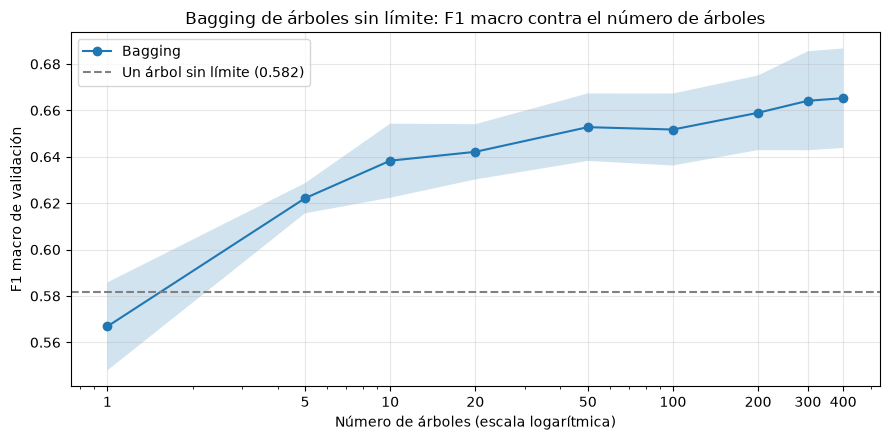

In [10]:
f1_arbol = TABLA_DESERCION["Árbol sin límite"]["F1 pliegues"]

fig, ax = plt.subplots(figsize=(9, 4.5))
media, desv = curva_bagging.mean(axis=0), curva_bagging.std(axis=0)
ax.plot(N_ARBOLES, media, marker="o", label="Bagging")
ax.fill_between(N_ARBOLES, media - desv, media + desv, alpha=0.2)
ax.axhline(f1_arbol.mean(), ls="--", color="gray", label=f"Un árbol sin límite ({f1_arbol.mean():.3f})")
ax.set_xscale("log")
ax.set_xticks(N_ARBOLES)
ax.set_xticklabels(N_ARBOLES)
ax.set_xlabel("Número de árboles (escala logarítmica)")
ax.set_ylabel("F1 macro de validación")
ax.set_title("Bagging de árboles sin límite: F1 macro contra el número de árboles")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Para la tabla final evaluamos *bagging* con 400 árboles con la misma función que los demás modelos.

In [11]:
pipe_bagging = Pipeline([
    ("prep", preprocesador(escalar=False)),
    ("modelo", BaggingClassifier(DecisionTreeClassifier(random_state=SEED), n_estimators=400,
                                 random_state=SEED, n_jobs=1)),
])
evaluar_desercion("Bagging (400 árboles)", pipe_bagging, "n_estimators=400")

Bagging (400 árboles): F1 macro = 0.6653 ± 0.0214 | sensibilidad = 0.337 | tiempo de entrenamiento = 11.50 s


### Resultados: ¿qué reduce *bagging*, y por qué?

El árbol sin límite de profundidad obtiene un F1 macro de 1.0 en entrenamiento pero de solo 0.5817 en validación. Es decir, se aprende de memoria a los estudiantes de entrenamiento y no generaliza bien, por lo que queda incluso por debajo del árbol podado de la Práctica 3 (0.6457).

Con *bagging* el F1 macro sube rápido en los primeros árboles: pasa de 0.567 con un árbol a 0.638 con 10 árboles, y después sigue subiendo más despacio hasta 0.665 con 400 árboles. Entre 200 y 400 árboles la mejora ya es de apenas 0.006, que es menor que la desviación estándar entre pliegues (0.021), entonces la curva está llegando a una meseta.

*Bagging* reduce la **varianza**. Cada árbol sin límite se ajusta demasiado a su muestra y comete errores que dependen de qué estudiantes le tocaron, pero como cada árbol se entrena con una muestra *bootstrap* distinta, esos errores no son los mismos en todos los árboles. Al juntar los votos de muchos árboles, los errores que se deben a la muestra se compensan entre sí y lo que queda es lo que los árboles tienen en común. Lo que *bagging* no puede cambiar es el sesgo de cada árbol, ya que todos los árboles son del mismo tipo, por eso la mejora tiene un límite.

Algo que vale la pena notar es que *bagging* (0.6653) supera al árbol de la Práctica 3 en F1 macro, pero su sensibilidad para *Enrolled* es mucho menor (0.337 contra 0.600). Esto se debe a que estos árboles no tienen pesos por clase, entonces al votar gana con más frecuencia la clase mayoritaria (*Graduate*) y se pierde la clase minoritaria.

## 4. Sesgo: tocón y *AdaBoost*

Un tocón es un árbol de profundidad 1, es decir, un árbol que solo hace una pregunta (un solo corte) y con eso decide la clase. Es un modelo demasiado simple para este problema, por lo que se equivoca aunque lo entrenemos con muchos datos, a esto se le conoce como **sesgo**.

*AdaBoost* entrena tocones uno después de otro. Después de cada ronda aumenta el peso de los estudiantes que se clasificaron mal, de esta forma el siguiente tocón se enfoca en ellos. La predicción final es una votación de todos los tocones, donde cada uno pesa según qué tan bien clasificó.

Primero evaluamos un solo tocón.

In [12]:
pipe_tocon = Pipeline([
    ("prep", preprocesador(escalar=False)),
    ("modelo", DecisionTreeClassifier(max_depth=1, random_state=SEED)),
])
evaluar_desercion("Tocón", pipe_tocon, "max_depth=1")

# Con un solo corte, ¿cuántas clases distintas puede predecir el tocón?
tocon = pipe_tocon.fit(X, y)
print("Clases que predice el tocón:", [CLASES[c] for c in np.unique(tocon.predict(X))])

Tocón: F1 macro = 0.4920 ± 0.0121 | sensibilidad = 0.000 | tiempo de entrenamiento = 0.03 s
Clases que predice el tocón: ['Dropout', 'Graduate']


Ahora construimos la curva de *AdaBoost* contra el número de rondas. En cada pliegue entrenamos *AdaBoost* con 400 tocones y usamos `staged_predict()`, que regresa las predicciones después de cada ronda sin tener que entrenar el modelo 400 veces. Calculamos el F1 macro tanto en validación como en entrenamiento, ya que en este caso nos interesa ver si el modelo logra aprender mejor los datos con los que se entrena.

In [13]:
from sklearn.ensemble import AdaBoostClassifier

RONDAS = 400
curva_ada_val = np.zeros((len(FOLDS), RONDAS))
curva_ada_ent = np.zeros((len(FOLDS), RONDAS))

inicio = time.perf_counter()
for k, (ent, val) in enumerate(FOLDS):
    prep = preprocesador(escalar=False).fit(X.iloc[ent])
    X_ent, X_val = prep.transform(X.iloc[ent]), prep.transform(X.iloc[val])

    ada = AdaBoostClassifier(DecisionTreeClassifier(max_depth=1), n_estimators=RONDAS,
                             random_state=SEED).fit(X_ent, y.iloc[ent])
    for j, pred in enumerate(ada.staged_predict(X_val)):
        curva_ada_val[k, j] = f1_score(y.iloc[val], pred, average="macro")
    for j, pred in enumerate(ada.staged_predict(X_ent)):
        curva_ada_ent[k, j] = f1_score(y.iloc[ent], pred, average="macro")
print(f"Tiempo de la curva: {time.perf_counter() - inicio:.1f} s")

rondas_tabla = [1, 5, 10, 20, 50, 100, 200, 300, 400]
display(pd.DataFrame({"Rondas": rondas_tabla,
                      "F1 entrenamiento": curva_ada_ent.mean(axis=0)[np.array(rondas_tabla) - 1],
                      "F1 validación": curva_ada_val.mean(axis=0)[np.array(rondas_tabla) - 1],
                      "Desv. est. validación": curva_ada_val.std(axis=0)[np.array(rondas_tabla) - 1]})
        .round(4).set_index("Rondas").T)

Tiempo de la curva: 9.4 s


Rondas,1,5,10,20,50,100,200,300,400
F1 entrenamiento,0.4920,0.4935,0.5177,0.5440,0.5662,0.6288,0.6440,0.6559,0.6622
F1 validación,0.4920,0.4935,0.5156,0.5378,0.5640,0.6116,0.6232,0.6405,0.6421
Desv. est. validación,0.0121,0.0095,0.0154,0.0184,0.0068,0.0098,0.0086,0.0166,0.0145


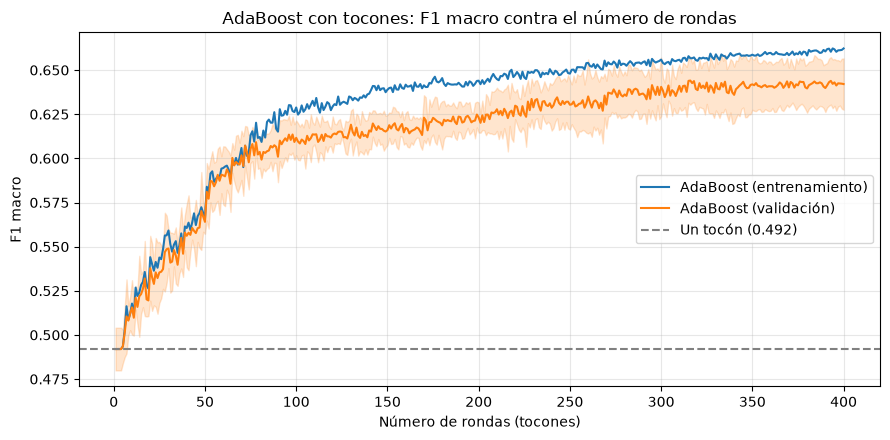

In [14]:
f1_tocon = TABLA_DESERCION["Tocón"]["F1 pliegues"]
rondas = np.arange(1, RONDAS + 1)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(rondas, curva_ada_ent.mean(axis=0), label="AdaBoost (entrenamiento)")
ax.plot(rondas, curva_ada_val.mean(axis=0), label="AdaBoost (validación)")
ax.fill_between(rondas, curva_ada_val.mean(axis=0) - curva_ada_val.std(axis=0),
                curva_ada_val.mean(axis=0) + curva_ada_val.std(axis=0), alpha=0.2, color="C1")
ax.axhline(f1_tocon.mean(), ls="--", color="gray", label=f"Un tocón ({f1_tocon.mean():.3f})")
ax.set_xlabel("Número de rondas (tocones)")
ax.set_ylabel("F1 macro")
ax.set_title("AdaBoost con tocones: F1 macro contra el número de rondas")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Para la tabla final evaluamos *AdaBoost* con 400 rondas.

In [15]:
pipe_ada = Pipeline([
    ("prep", preprocesador(escalar=False)),
    ("modelo", AdaBoostClassifier(DecisionTreeClassifier(max_depth=1), n_estimators=400,
                                  random_state=SEED)),
])
evaluar_desercion("AdaBoost (400 tocones)", pipe_ada, "n_estimators=400")

AdaBoost (400 tocones): F1 macro = 0.6421 ± 0.0145 | sensibilidad = 0.261 | tiempo de entrenamiento = 1.25 s


### Resultados: ¿qué reduce *boosting*, y por qué?

El tocón obtiene un F1 macro de 0.4920 y una sensibilidad de 0 para *Enrolled*. Con un solo corte el tocón solo puede separar a los estudiantes en dos grupos, entonces solo predice *Dropout* o *Graduate* y nunca predice *Enrolled*. Este es un ejemplo claro de un modelo con mucho **sesgo**: es demasiado simple para el problema.

Con *AdaBoost* el F1 macro sube de forma constante con las rondas: 0.516 con 10 tocones, 0.612 con 100 y 0.642 con 400. A diferencia de *bagging*, en este caso las curvas de entrenamiento y de validación suben juntas y quedan muy cerca una de otra (0.662 y 0.642 con 400 rondas). Esto indica que el modelo no está memorizando el entrenamiento, sino que cada vez aprende mejor los patrones de los datos. Entre 300 y 400 rondas la mejora ya es de apenas 0.002, entonces la curva también llega a una meseta.

*Boosting* reduce el **sesgo**. Un tocón por sí solo no puede representar una frontera complicada, pero cada tocón nuevo se enfoca en los estudiantes que los anteriores clasificaron mal, y al sumar cientos de cortes sencillos se va construyendo una frontera mucho más compleja que la de un solo tocón. Por eso el error baja tanto en entrenamiento como en validación, que es justo lo que se espera cuando se reduce el sesgo y no la varianza.

Aun así, *AdaBoost* (0.6421) no supera al árbol de la Práctica 3 y tiene una sensibilidad muy baja para *Enrolled* (0.261), ya que tampoco usa pesos por clase.

## 5. Combinar los cinco clasificadores base

En esta fase combinamos los cinco clasificadores de la Práctica 3 de tres formas:

- **Votación dura.** Cada clasificador vota por una clase y gana la clase con más votos.
- **Votación suave.** Cada clasificador da la probabilidad de cada clase, se promedian las probabilidades de los cinco y gana la clase con el promedio más alto.
- ***Stacking*.** Las probabilidades de los cinco clasificadores se usan como atributos de un sexto modelo (el meta-modelo), en este caso una regresión logística, que aprende cuánto confiar en cada clasificador.

La votación suave y el *stacking* necesitan probabilidades, pero el SVM no las da directamente. Para obtenerlas usamos `CalibratedClassifierCV`, que separa el entrenamiento en partes, entrena el SVM con unas y con las otras aprende a convertir su salida en probabilidades. Como el SVM calibrado queda dentro del ensamble, y el ensamble se evalúa con `cross_validate`, la calibración se hace únicamente con los estudiantes de la partición de entrenamiento de cada pliegue.

In [16]:
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import VotingClassifier, StackingClassifier

svm_calibrado = CalibratedClassifierCV(pipe_svm, cv=5)

# Para la votación dura no se necesitan probabilidades, usamos el SVM original
base_dura = [("arbol", pipe_arbol), ("nb", pipe_nb), ("knn", pipe_knn),
             ("svm", pipe_svm), ("lr", pipe_lr)]
# Para la votación suave y el stacking usamos el SVM calibrado
base_prob = [("arbol", pipe_arbol), ("nb", pipe_nb), ("knn", pipe_knn),
             ("svm", svm_calibrado), ("lr", pipe_lr)]

votacion_dura = VotingClassifier(base_dura, voting="hard")
votacion_suave = VotingClassifier(base_prob, voting="soft")
stacking = StackingClassifier(base_prob, final_estimator=LogisticRegression(max_iter=1000),
                              cv=5)

evaluar_desercion("Votación dura", votacion_dura, "5 clasificadores base")
evaluar_desercion("Votación suave", votacion_suave, "5 base, SVM calibrado")
evaluar_desercion("Stacking", stacking, "5 base, SVM calibrado, meta-modelo logístico")

Votación dura: F1 macro = 0.6891 ± 0.0052 | sensibilidad = 0.559 | tiempo de entrenamiento = 0.91 s


Votación suave: F1 macro = 0.6740 ± 0.0102 | sensibilidad = 0.425 | tiempo de entrenamiento = 2.44 s


Stacking: F1 macro = 0.6689 ± 0.0122 | sensibilidad = 0.346 | tiempo de entrenamiento = 12.31 s


Para saber qué tan correlacionados están los errores de los cinco clasificadores, generamos sus predicciones de validación cruzada (cada estudiante es clasificado por el modelo entrenado en los pliegues donde él no estaba) y marcamos con 1 los estudiantes en los que cada clasificador se equivoca y con 0 los que acierta. Después calculamos la correlación entre esas columnas: una correlación cercana a 1 indica que dos clasificadores se equivocan en los mismos estudiantes.

Proporción de errores de cada clasificador:


,Árbol de decisión,Naive Bayes,kNN,SVM,Regresión logística
Error,0.319,0.327,0.318,0.277,0.276


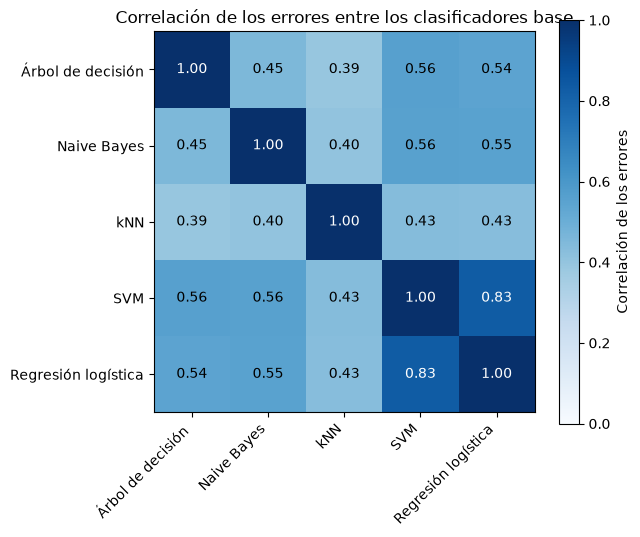

In [17]:
from sklearn.model_selection import cross_val_predict

PRED_BASE = {nombre: cross_val_predict(modelo, X, y, cv=FOLDS, n_jobs=-1)
             for nombre, modelo in BASE.items()}
errores = pd.DataFrame({nombre: (pred != y.to_numpy()).astype(int)
                        for nombre, pred in PRED_BASE.items()})

print("Proporción de errores de cada clasificador:")
display(errores.mean().round(3).to_frame("Error").T)

corr = errores.corr()
fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(corr, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(corr)))
ax.set_xticklabels(corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr)))
ax.set_yticklabels(corr.index)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center",
                color="white" if corr.iloc[i, j] > 0.6 else "black")
fig.colorbar(im, ax=ax, label="Correlación de los errores")
ax.set_title("Correlación de los errores entre los clasificadores base")
plt.tight_layout()
plt.show()

Para ver lo mismo de otra forma, contamos en cuántos estudiantes se equivocan 0, 1, 2, 3, 4 o los 5 clasificadores al mismo tiempo. Si los errores fueran independientes, sería muy raro que los cinco se equivocaran en el mismo estudiante.

In [18]:
cuantos = errores.sum(axis=1).value_counts().sort_index()
display(pd.DataFrame({"Estudiantes": cuantos,
                      "%": (100 * cuantos / len(y)).round(1)})
        .rename_axis("Clasificadores que se equivocan").T)

# Si los errores fueran independientes, ¿cuántos estudiantes esperaríamos con los 5 equivocados?
print(f"Estudiantes con los 5 equivocados: {(errores.sum(axis=1) == 5).mean():.3f} "
      f"| esperado si los errores fueran independientes: {errores.mean().prod():.4f}")

Clasificadores que se equivocan,0,1,2,3,4,5
Estudiantes,1614.0,607.0,320.0,269.0,335.0,394.0
%,45.6,17.2,9.0,7.6,9.5,11.1


Estudiantes con los 5 equivocados: 0.111 | esperado si los errores fueran independientes: 0.0025


### Resultados: ¿qué tan correlacionados están los errores y qué implica?

Los errores de los cinco clasificadores están bastante correlacionados. La correlación más alta es entre el SVM y la regresión logística (0.83), lo cual tiene sentido porque en la Práctica 3 vimos que los dos construyen fronteras parecidas y obtienen casi el mismo resultado. Entre los demás pares la correlación va de 0.39 a 0.56, y kNN es el que tiene los errores menos parecidos a los demás.

La tabla de conteo lo muestra de otra forma. El 11.1 % de los estudiantes es clasificado mal por los cinco clasificadores al mismo tiempo, mientras que si los errores fueran independientes esperaríamos solo el 0.25 %. Es decir, hay un grupo de estudiantes que es difícil para todos los modelos, por ejemplo los desertores que en el primer semestre se parecen a los estudiantes inscritos, como vimos en la Práctica 3.

Esto implica que combinar los cinco clasificadores tiene una ganancia limitada. Un ensamble solo puede corregir un error si la mayoría de los clasificadores acierta en ese estudiante, y cuando todos se equivocan juntos no hay forma de corregirlo. Esto es justo lo que vemos en los resultados:

- **Votación dura** obtuvo un F1 macro de 0.6891 ± 0.0052, apenas 0.006 más que el SVM (0.6828), una diferencia de aproximadamente una desviación estándar.
- **Votación suave** (0.6740) y ***stacking*** (0.6689) quedaron por debajo del SVM. En los dos casos la sensibilidad de *Enrolled* baja mucho (0.425 y 0.346). En la votación suave se promedian las probabilidades, y esto puede deberse a que Naive Bayes y kNN, que no tienen pesos por clase, empujan el promedio hacia las clases grandes. En el *stacking*, el meta-modelo es una regresión logística sin pesos por clase, entonces aprende a favorecer a *Graduate* y *Dropout*, que son las clases con más estudiantes.

Así pues, la votación dura fue la única combinación que mejoró un poco al mejor clasificador base, y la mejora es pequeña porque los clasificadores se equivocan en los mismos estudiantes. Además, el *stacking* tarda mucho más en entrenarse que cualquier clasificador base (más de diez veces lo que tarda el SVM por pliegue), ya que entrena varias veces a cada clasificador base.

## 6. *Bagging* optimizado: *Random Forest* y *Extra-Trees*

En la fase 3 vimos que *bagging* reduce la varianza al promediar árboles, pero también vimos que su ganancia tiene un límite, porque todos los árboles usan los mismos atributos y terminan siendo parecidos entre sí. *Random Forest* y *Extra-Trees* agregan más aleatoriedad para que los árboles sean más distintos:

- ***Random Forest*** en cada corte solo considera un subconjunto aleatorio de atributos (`max_features`).
- ***Extra-Trees*** además elige el punto de corte al azar en lugar de buscar el mejor, y por defecto no usa muestras *bootstrap* sino todos los estudiantes.

Para la búsqueda de hiperparámetros reutilizamos la idea de la Práctica 3: una búsqueda aleatoria con `RandomizedSearchCV`, los mismos cinco pliegues y el F1 macro como métrica. Evaluamos 60 configuraciones de cada modelo para cumplir con el mínimo de 50 con un pequeño margen.

In [19]:
from sklearn.model_selection import RandomizedSearchCV

BUSQUEDAS = {}


def buscar(nombre, pipeline, espacio, n_iter=60):
    busqueda = RandomizedSearchCV(pipeline, espacio, n_iter=n_iter, scoring="f1_macro",
                                  cv=FOLDS, random_state=SEED, n_jobs=-1)
    inicio = time.perf_counter()
    busqueda.fit(X, y)
    duracion = time.perf_counter() - inicio

    BUSQUEDAS[nombre] = busqueda
    i = busqueda.best_index_
    print(f"{nombre}: {len(busqueda.cv_results_['params'])} configuraciones evaluadas")
    print(f"  F1 macro = {busqueda.best_score_:.4f} ± {busqueda.cv_results_['std_test_score'][i]:.4f}")
    print(f"  Tiempo de la búsqueda = {duracion:.1f} s")
    print(f"  Mejores hiperparámetros: {resumir(busqueda.best_params_)}")
    return busqueda


def resumir(params):
    # Convierte los hiperparámetros en un texto corto para la tabla
    partes = []
    for k, v in params.items():
        k = k.replace("modelo__", "")
        if isinstance(v, (float, np.floating)):
            partes.append(f"{k}={v:.3g}")
        else:
            partes.append(f"{k}={v}")
    return ", ".join(partes)

Definimos una función para la gráfica de la meseta, igual que en la Práctica 3. La primera gráfica muestra el mejor F1 macro alcanzado contra el número de configuraciones evaluadas: si la curva deja de subir, evaluar más configuraciones ya no mejora el resultado. La segunda muestra el F1 macro de cada configuración contra uno de sus hiperparámetros, con un color distinto según otro hiperparámetro.

In [20]:
def graficar_meseta(nombre, parametro, etiqueta, color_por, escala_log=False):
    r = pd.DataFrame(BUSQUEDAS[nombre].cv_results_)
    f1 = r["mean_test_score"].to_numpy()

    fig, ax = plt.subplots(1, 2, figsize=(13, 4))

    ax[0].plot(np.arange(1, len(f1) + 1), np.maximum.accumulate(f1), marker=".")
    ax[0].set_xlabel("Configuraciones evaluadas")
    ax[0].set_ylabel("Mejor F1 macro alcanzado")
    ax[0].set_title(f"{nombre}: convergencia de la búsqueda")
    ax[0].grid(alpha=0.3)

    grupos = r[f"param_{color_por}"].map(lambda v: "None" if pd.isna(v) else str(v))
    for valor in sorted(grupos.unique()):
        sel = grupos == valor
        ax[1].scatter(pd.to_numeric(r.loc[sel, f"param_{parametro}"]), f1[sel], alpha=0.7,
                      label=f"{color_por.replace('modelo__', '')} = {valor}")
    if escala_log:
        ax[1].set_xscale("log")
    ax[1].set_xlabel(etiqueta)
    ax[1].set_ylabel("F1 macro de validación")
    ax[1].set_title(f"{nombre}: F1 macro contra {etiqueta}")
    ax[1].legend(fontsize=8)
    ax[1].grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

El espacio de búsqueda de *Random Forest* incluye la fracción de atributos que se consideran en cada corte (`max_features`, de 0.05 a 0.8), el número mínimo de estudiantes por hoja (de 1 a 30), la profundidad máxima (de 5 a 30, o sin límite), el criterio de división (Gini o entropía) y los pesos por clase. En los pesos, además de `"balanced"`, probamos `"balanced_subsample"`, que calcula los pesos con la muestra *bootstrap* de cada árbol. El número de árboles se fijó en 300, ya que en la curva de *bagging* el F1 ya no cambia después de 200 árboles.

In [21]:
from scipy.stats import randint, uniform, loguniform
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier

pipe_rf = Pipeline([
    ("prep", preprocesador(escalar=False)),
    ("modelo", RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=1)),
])

espacio_rf = {
    "modelo__max_features": uniform(0.05, 0.75),
    "modelo__min_samples_leaf": randint(1, 31),
    "modelo__max_depth": [5, 10, 15, 20, 30, None],
    "modelo__criterion": ["gini", "entropy"],
    "modelo__class_weight": [None, "balanced", "balanced_subsample"],
}

busqueda_rf = buscar("Random Forest", pipe_rf, espacio_rf)

Random Forest: 60 configuraciones evaluadas
  F1 macro = 0.6823 ± 0.0108
  Tiempo de la búsqueda = 114.1 s
  Mejores hiperparámetros: class_weight=balanced, criterion=gini, max_depth=20, max_features=0.187, min_samples_leaf=4


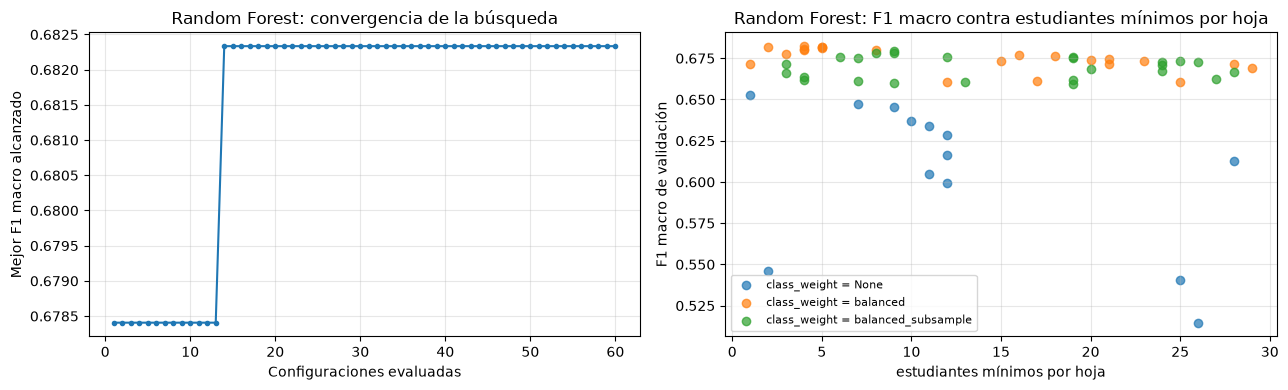

In [22]:
graficar_meseta("Random Forest", "modelo__min_samples_leaf", "estudiantes mínimos por hoja",
                color_por="modelo__class_weight")

Para *Extra-Trees* usamos el mismo espacio de búsqueda, y agregamos `bootstrap` para probar si conviene entrenar cada árbol con una muestra *bootstrap* o con todos los estudiantes.

In [23]:
pipe_et = Pipeline([
    ("prep", preprocesador(escalar=False)),
    ("modelo", ExtraTreesClassifier(n_estimators=300, random_state=SEED, n_jobs=1)),
])

espacio_et = dict(espacio_rf)
espacio_et["modelo__bootstrap"] = [True, False]

busqueda_et = buscar("Extra-Trees", pipe_et, espacio_et)

Extra-Trees: 60 configuraciones evaluadas
  F1 macro = 0.6738 ± 0.0043
  Tiempo de la búsqueda = 89.6 s
  Mejores hiperparámetros: bootstrap=False, class_weight=balanced, criterion=entropy, max_depth=15, max_features=0.539, min_samples_leaf=9


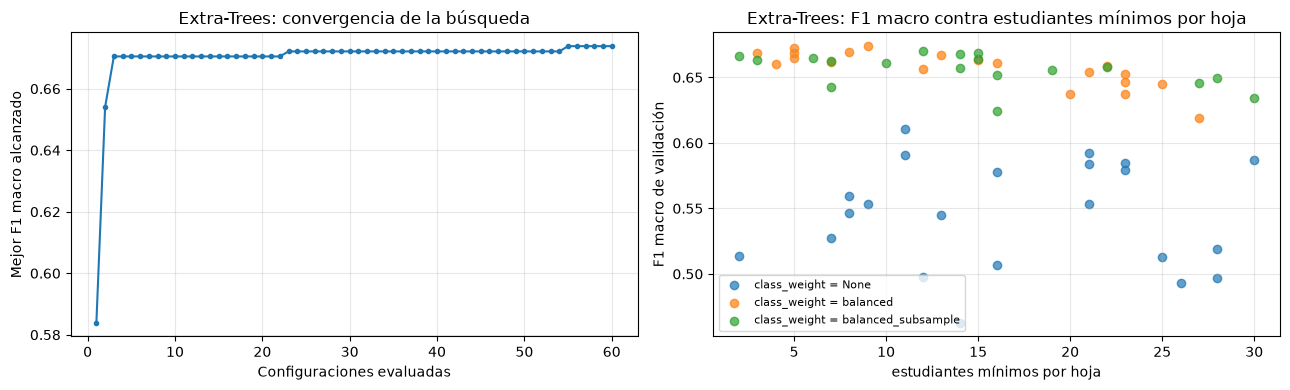

In [24]:
graficar_meseta("Extra-Trees", "modelo__min_samples_leaf", "estudiantes mínimos por hoja",
                color_por="modelo__class_weight")

Evaluamos la mejor configuración de cada búsqueda con la función `evaluar_desercion`, para obtener la sensibilidad de *Enrolled* y el tiempo de entrenamiento de la misma forma que en los demás modelos.

In [25]:
for nombre in ["Random Forest", "Extra-Trees"]:
    b = BUSQUEDAS[nombre]
    evaluar_desercion(nombre, b.best_estimator_, resumir(b.best_params_))

Random Forest: F1 macro = 0.6823 ± 0.0108 | sensibilidad = 0.542 | tiempo de entrenamiento = 1.79 s


Extra-Trees: F1 macro = 0.6738 ± 0.0043 | sensibilidad = 0.550 | tiempo de entrenamiento = 3.13 s


### Resultados de *Random Forest* y *Extra-Trees*

El mejor *Random Forest* obtuvo un F1 macro de 0.6823 ± 0.0108, con `max_features` ≈ 0.19, al menos 4 estudiantes por hoja, profundidad máxima de 20, criterio Gini y pesos balanceados. El mejor *Extra-Trees* obtuvo 0.6738 ± 0.0043, sin *bootstrap*, con `max_features` ≈ 0.54, al menos 9 estudiantes por hoja, profundidad máxima de 15, criterio de entropía y pesos balanceados.

En la gráfica de convergencia de *Random Forest* el mejor resultado se alcanza en la configuración 14 y después la curva queda plana durante las 46 configuraciones restantes. En *Extra-Trees* la curva sube rápido en las primeras 3 configuraciones y después solo mejora en milésimas (en las configuraciones 23 y 55), entonces podemos decir que las dos búsquedas llegaron a una meseta.

En las gráficas de la derecha se ve que el hiperparámetro más influyente son los pesos por clase. Las configuraciones sin pesos (`None`) quedan claramente por debajo de las demás, sobre todo en *Extra-Trees*, donde llegan a bajar hasta 0.46. Con pesos balanceados, ya sea `"balanced"` o `"balanced_subsample"`, casi todas las configuraciones quedan entre 0.65 y 0.68, sin importar mucho el número de estudiantes por hoja. Comparado con el *bagging* de la fase 3 (0.6653), *Random Forest* mejora el F1 macro y sobre todo la sensibilidad de *Enrolled* (de 0.337 a 0.542). Esto se debe principalmente a los pesos por clase y a que, al usar solo una parte de los atributos en cada corte, los árboles son más distintos entre sí.

Aun así, *Random Forest* (0.6823) prácticamente empata con el SVM (0.6828) y la regresión logística (0.6824), y *Extra-Trees* queda un poco por debajo. Entonces, una vez que los clasificadores base están bien ajustados, *bagging* optimizado no logra superarlos.

## 7. *Boosting* optimizado: XGBoost y LightGBM

XGBoost y LightGBM son dos bibliotecas de *gradient boosting*. La idea es parecida a *AdaBoost*: se entrenan árboles uno después de otro y cada árbol nuevo intenta corregir los errores de los anteriores. La diferencia es que, en lugar de cambiar los pesos de los estudiantes, cada árbol nuevo se ajusta a lo que le falta a la predicción actual para llegar a la clase correcta. Además, estas bibliotecas incluyen varias formas de regularización para que los árboles no se ajusten demasiado al entrenamiento.

Los hiperparámetros que optimizamos son:

- **Tasa de aprendizaje** (`learning_rate`): qué tanto aporta cada árbol nuevo. Con una tasa pequeña cada árbol corrige poco y se necesitan más árboles.
- **Número de árboles** (`n_estimators`), que depende de la tasa de aprendizaje.
- **Tamaño de los árboles**: la profundidad máxima en XGBoost y el número de hojas en LightGBM.
- **Regularización de las hojas** (`reg_lambda`): castiga los valores grandes en las hojas, de forma parecida a la regularización L2 de la regresión logística.
- **Submuestreo de filas** (`subsample`) y **de columnas** (`colsample_bytree`): cada árbol se entrena con una parte de los estudiantes y de los atributos, una idea parecida a la de *Random Forest*.
- **Pesos por clase**, sin pesos o balanceados.

LightGBM tiene el parámetro `class_weight`, pero XGBoost no lo tiene cuando hay más de dos clases. Lo que sí acepta XGBoost es un peso para cada estudiante (`sample_weight`) al momento de entrenar. Por eso creamos una versión de `XGBClassifier` que agrega el parámetro `class_weight`: cuando vale `"balanced"`, calcula el peso de cada estudiante según su clase con `compute_sample_weight` y se lo pasa a XGBoost. De esta forma los pesos se calculan solo con los estudiantes de entrenamiento de cada pliegue y se pueden incluir en la búsqueda igual que en los otros modelos.

In [26]:
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.utils.class_weight import compute_sample_weight


class XGBConPesos(XGBClassifier):
    def __init__(self, class_weight=None, **kwargs):
        super().__init__(**kwargs)
        self.class_weight = class_weight

    def get_xgb_params(self):
        # class_weight no es un parámetro de XGBoost, entonces no se lo pasamos
        params = super().get_xgb_params()
        params.pop("class_weight", None)
        return params

    def fit(self, X, y, **kwargs):
        if self.class_weight == "balanced":
            kwargs["sample_weight"] = compute_sample_weight("balanced", y)
        return super().fit(X, y, **kwargs)

El espacio de búsqueda de XGBoost incluye el número de árboles (de 100 a 600), la tasa de aprendizaje (de 0.01 a 0.3, en escala logarítmica), la profundidad máxima (de 2 a 8), la regularización de las hojas `reg_lambda` (de 0.1 a 20), el submuestreo de filas y de columnas (de 0.5 a 1) y los pesos por clase. Se evaluaron 60 configuraciones.

In [27]:
pipe_xgb = Pipeline([
    ("prep", preprocesador(escalar=False)),
    ("modelo", XGBConPesos(tree_method="hist", random_state=SEED, n_jobs=1)),
])

espacio_xgb = {
    "modelo__n_estimators": randint(100, 601),
    "modelo__learning_rate": loguniform(0.01, 0.3),
    "modelo__max_depth": randint(2, 9),
    "modelo__reg_lambda": loguniform(0.1, 20),
    "modelo__subsample": uniform(0.5, 0.5),
    "modelo__colsample_bytree": uniform(0.5, 0.5),
    "modelo__class_weight": [None, "balanced"],
}

busqueda_xgb = buscar("XGBoost", pipe_xgb, espacio_xgb)

XGBoost: 60 configuraciones evaluadas
  F1 macro = 0.6934 ± 0.0155
  Tiempo de la búsqueda = 41.6 s
  Mejores hiperparámetros: class_weight=balanced, colsample_bytree=0.949, learning_rate=0.0787, max_depth=4, n_estimators=211, reg_lambda=0.171, subsample=0.832


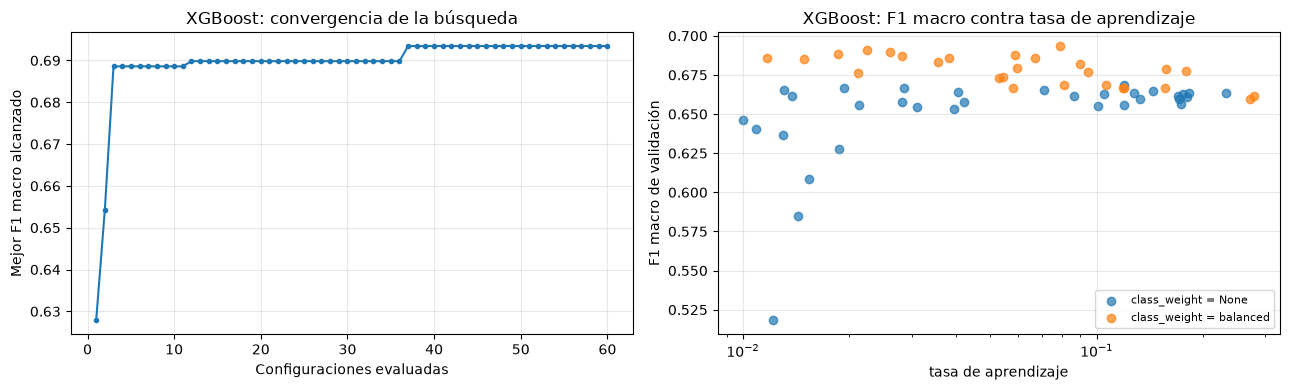

In [28]:
graficar_meseta("XGBoost", "modelo__learning_rate", "tasa de aprendizaje",
                color_por="modelo__class_weight", escala_log=True)

El espacio de búsqueda de LightGBM es parecido. En lugar de la profundidad usamos el número máximo de hojas de cada árbol (`num_leaves`, de 4 a 63), y agregamos el número mínimo de estudiantes por hoja (`min_child_samples`, de 5 a 60). En LightGBM el submuestreo de filas solo se aplica si se indica cada cuántos árboles se toma una nueva muestra, por eso fijamos `subsample_freq=1`, es decir, una muestra nueva para cada árbol.

In [29]:
pipe_lgbm = Pipeline([
    ("prep", preprocesador(escalar=False)),
    ("modelo", LGBMClassifier(subsample_freq=1, random_state=SEED, n_jobs=1, verbose=-1)),
])

espacio_lgbm = {
    "modelo__n_estimators": randint(100, 601),
    "modelo__learning_rate": loguniform(0.01, 0.3),
    "modelo__num_leaves": randint(4, 64),
    "modelo__min_child_samples": randint(5, 61),
    "modelo__reg_lambda": loguniform(0.1, 20),
    "modelo__subsample": uniform(0.5, 0.5),
    "modelo__colsample_bytree": uniform(0.5, 0.5),
    "modelo__class_weight": [None, "balanced"],
}

busqueda_lgbm = buscar("LightGBM", pipe_lgbm, espacio_lgbm)

LightGBM: 60 configuraciones evaluadas
  F1 macro = 0.6926 ± 0.0181
  Tiempo de la búsqueda = 38.7 s
  Mejores hiperparámetros: class_weight=balanced, colsample_bytree=0.99, learning_rate=0.0182, min_child_samples=20, n_estimators=317, num_leaves=29, reg_lambda=1.35, subsample=0.737


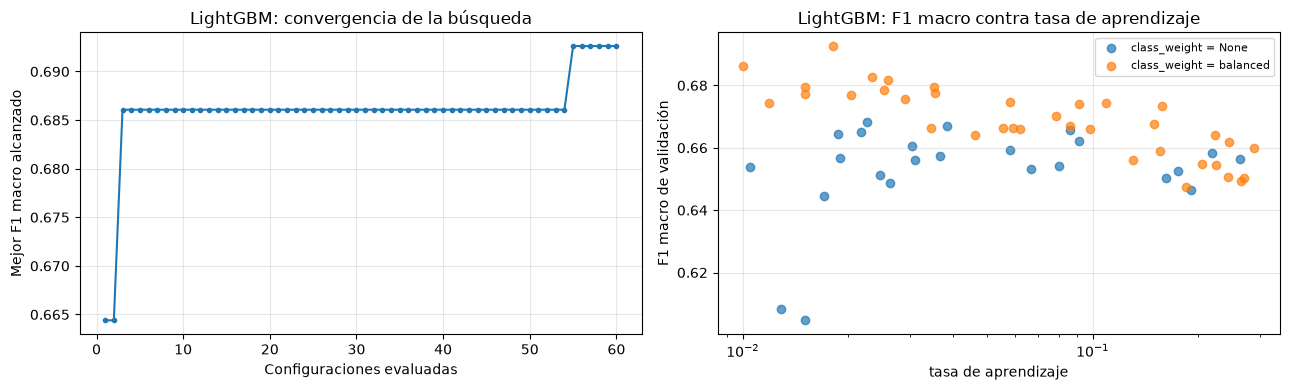

In [30]:
graficar_meseta("LightGBM", "modelo__learning_rate", "tasa de aprendizaje",
                color_por="modelo__class_weight", escala_log=True)

In [31]:
for nombre in ["XGBoost", "LightGBM"]:
    b = BUSQUEDAS[nombre]
    evaluar_desercion(nombre, b.best_estimator_, resumir(b.best_params_))

XGBoost: F1 macro = 0.6934 ± 0.0155 | sensibilidad = 0.557 | tiempo de entrenamiento = 0.37 s


LightGBM: F1 macro = 0.6926 ± 0.0181 | sensibilidad = 0.532 | tiempo de entrenamiento = 0.65 s


### Resultados de XGBoost y LightGBM

El mejor XGBoost obtuvo un F1 macro de 0.6934 ± 0.0155, con 211 árboles, tasa de aprendizaje ≈ 0.079, profundidad máxima de 4, `reg_lambda` ≈ 0.17, submuestreo de filas ≈ 0.83, de columnas ≈ 0.95 y pesos balanceados. El mejor LightGBM obtuvo 0.6926 ± 0.0181, con 317 árboles, tasa de aprendizaje ≈ 0.018, 29 hojas, al menos 20 estudiantes por hoja, `reg_lambda` ≈ 1.35, submuestreo de filas ≈ 0.74, de columnas ≈ 0.99 y pesos balanceados.

En la gráfica de convergencia de XGBoost la última mejora ocurre en la configuración 37 y después la curva queda plana durante las 23 restantes. En LightGBM hay una mejora en la configuración 55, pero es de 0.0066, que es menor que la desviación estándar entre pliegues (0.018), así pues la diferencia con la configuración anterior está dentro de la variabilidad de la validación cruzada y podemos decir que la búsqueda también llegó a una meseta.

En las dos bibliotecas el hiperparámetro más influyente son los pesos por clase: casi todas las configuraciones con pesos balanceados quedan por encima de las que no tienen pesos. En cuanto a la tasa de aprendizaje, en XGBoost las mejores configuraciones están entre 0.02 y 0.1, y en LightGBM las tasas más altas (mayores a 0.15) tienden a dar resultados un poco peores, ya que cada árbol corrige demasiado y el modelo se ajusta más al entrenamiento.

XGBoost y LightGBM son los dos mejores modelos hasta ahora, pero su ventaja sobre el SVM (0.6828) es de apenas 0.010–0.011, que es menor que su propia desviación estándar entre pliegues (0.016–0.018). Además, son mucho más rápidos que *Random Forest*: en nuestra ejecución, la búsqueda completa de XGBoost tardó menos de la mitad que la de *Random Forest*.

## 8. Comparación de todos los modelos

En esta fase juntamos en una tabla todos los modelos evaluados en la Parte 1, ordenados por su F1 macro promedio. Para cada modelo reportamos el F1 macro (media ± desviación estándar entre los 5 pliegues), la sensibilidad de *Enrolled*, el tiempo promedio de entrenamiento en un pliegue y, en los modelos optimizados, la mejor configuración encontrada.

In [32]:
def construir_tabla(tabla, nombre_sens):
    filas = []
    for nombre, r in tabla.items():
        f1 = r["F1 pliegues"]
        filas.append({"Modelo": nombre,
                      "media": f1.mean(),
                      "F1 macro (media ± desv.)": f"{f1.mean():.4f} ± {f1.std():.4f}",
                      nombre_sens: round(r["Sensibilidad"], 3),
                      "Tiempo de entrenamiento (s)": round(r["Tiempo (s)"], 2),
                      "Configuración": r["Configuración"]})
    return (pd.DataFrame(filas).sort_values("media", ascending=False)
            .drop(columns="media").set_index("Modelo"))


comparacion = construir_tabla(TABLA_DESERCION, "Sensibilidad Enrolled")
display(comparacion)

,F1 macro (media ± desv.),Sensibilidad Enrolled,Tiempo de entrenamiento (s),Configuración
Modelo,,,,
XGBoost,0.6934 ± 0.0155,0.557,0.37,"class_weight=balanced, colsample_bytree=0.949, learning_rate=0.0787, max_depth=4, n_estimators=211, reg_lambda=0.171, subsample=0.832"
LightGBM,0.6926 ± 0.0181,0.532,0.65,"class_weight=balanced, colsample_bytree=0.99, learning_rate=0.0182, min_child_samples=20, n_estimators=317, num_leaves=29, reg_lambda=1.35, subsample=0.737"
Votación dura,0.6891 ± 0.0052,0.559,0.91,5 clasificadores base
SVM,0.6828 ± 0.0052,0.608,0.67,
Regresión logística,0.6824 ± 0.0084,0.575,0.32,
Random Forest,0.6823 ± 0.0108,0.542,1.79,"class_weight=balanced, criterion=gini, max_depth=20, max_features=0.187, min_samples_leaf=4"
Votación suave,0.6740 ± 0.0102,0.425,2.44,"5 base, SVM calibrado"
Extra-Trees,0.6738 ± 0.0043,0.550,3.13,"bootstrap=False, class_weight=balanced, criterion=entropy, max_depth=15, max_features=0.539, min_samples_leaf=9"
Stacking,0.6689 ± 0.0122,0.346,12.31,"5 base, SVM calibrado, meta-modelo logístico"


Graficamos el F1 macro de cada modelo con su desviación estándar, separando por color los clasificadores base y cada familia de ensambles.

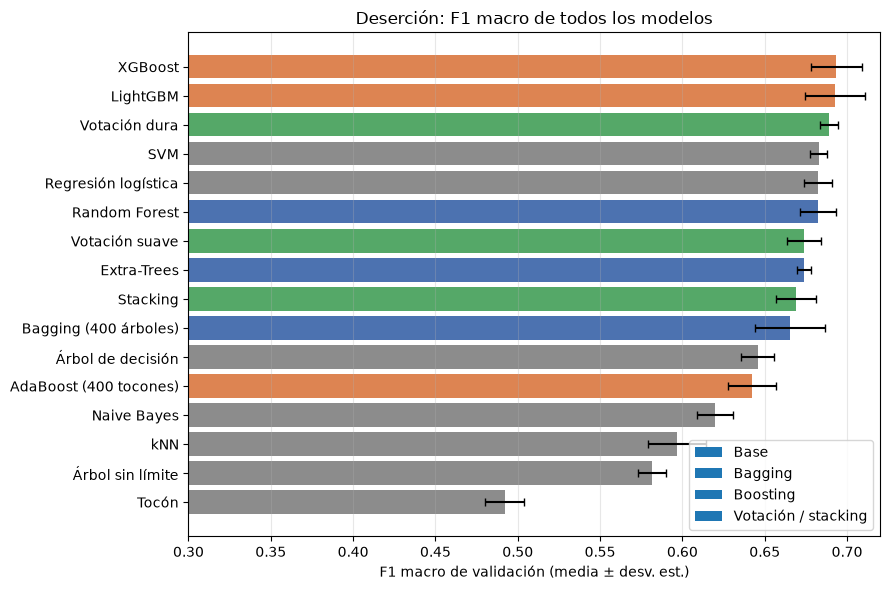

In [33]:
FAMILIA = {
    "Árbol de decisión": "Base", "Naive Bayes": "Base", "kNN": "Base", "SVM": "Base",
    "Regresión logística": "Base", "Árbol sin límite": "Base", "Tocón": "Base",
    "Bagging (400 árboles)": "Bagging", "Random Forest": "Bagging", "Extra-Trees": "Bagging",
    "AdaBoost (400 tocones)": "Boosting", "XGBoost": "Boosting", "LightGBM": "Boosting",
    "Votación dura": "Votación / stacking", "Votación suave": "Votación / stacking",
    "Stacking": "Votación / stacking",
}
COLORES = {"Base": "#8c8c8c", "Bagging": "#4c72b0", "Boosting": "#dd8452",
           "Votación / stacking": "#55a868"}

medias = {n: r["F1 pliegues"].mean() for n, r in TABLA_DESERCION.items()}
desvs = {n: r["F1 pliegues"].std() for n, r in TABLA_DESERCION.items()}
orden = sorted(medias, key=medias.get)

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(orden, [medias[n] for n in orden], xerr=[desvs[n] for n in orden], capsize=3,
        color=[COLORES[FAMILIA[n]] for n in orden])
for familia, color in COLORES.items():
    ax.barh([], [], color=color, label=familia)
ax.set_xlim(0.3, 0.72)
ax.set_xlabel("F1 macro de validación (media ± desv. est.)")
ax.set_title("Deserción: F1 macro de todos los modelos")
ax.legend(loc="lower right")
ax.grid(alpha=0.3, axis="x")
plt.tight_layout()
plt.show()

Mostramos la matriz de confusión únicamente del mejor modelo, con predicciones de validación cruzada sobre los mismos pliegues, en número de estudiantes y normalizada por fila (la diagonal es la sensibilidad de cada clase).

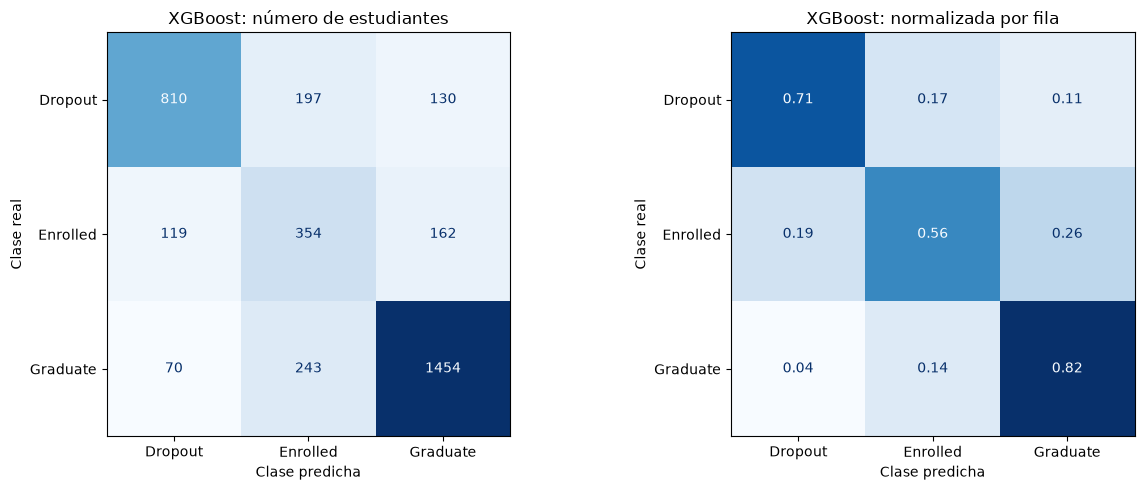

In [34]:
from sklearn.metrics import ConfusionMatrixDisplay

MEJOR_DESERCION = comparacion.index[0]
pred_mejor = cross_val_predict(MODELOS_DESERCION[MEJOR_DESERCION], X, y, cv=FOLDS, n_jobs=-1)

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay.from_predictions(y, pred_mejor, display_labels=CLASES, ax=ax[0],
                                        cmap="Blues", colorbar=False)
ax[0].set_title(f"{MEJOR_DESERCION}: número de estudiantes")
ConfusionMatrixDisplay.from_predictions(y, pred_mejor, display_labels=CLASES, ax=ax[1],
                                        cmap="Blues", colorbar=False, normalize="true",
                                        values_format=".2f")
ax[1].set_title(f"{MEJOR_DESERCION}: normalizada por fila")
for a in ax:
    a.set_xlabel("Clase predicha")
    a.set_ylabel("Clase real")
plt.tight_layout()
plt.show()

### Resultados de la comparación

El mejor modelo de la deserción es XGBoost, con un F1 macro de 0.6934 ± 0.0155, seguido de LightGBM (0.6926) y la votación dura (0.6891). Después aparecen tres modelos prácticamente empatados: el SVM (0.6828), la regresión logística (0.6824) y *Random Forest* (0.6823). Los modelos sin pesos por clase, como *bagging*, *AdaBoost*, el árbol sin límite y el tocón, quedan en la parte de abajo de la tabla y tienen las sensibilidades más bajas de *Enrolled*.

Respondiendo a la pregunta de la práctica, los ensambles ganan **muy poco** sobre los clasificadores base cuando estos ya están bien ajustados. La mejor ganancia es la de XGBoost, de 0.011 sobre el SVM, que es menor que la desviación estándar entre pliegues, entonces no podemos afirmar que XGBoost sea realmente mejor que el SVM. Además, el SVM sigue teniendo la sensibilidad más alta para *Enrolled* (0.608 contra 0.557 de XGBoost).

En la matriz de confusión de XGBoost se observa que identifica correctamente al 71 % de los desertores (810 de 1137), un poco más que el SVM de la Práctica 3 (67.2 %), y al 82 % de los graduados. La clase más difícil sigue siendo *Enrolled*, ya que el 26 % de estos estudiantes se confunde con *Graduate* y el 19 % con *Dropout*. Al igual que en la Práctica 3, la principal confusión de los desertores es con *Enrolled* (17 %), lo cual confirma que hay un grupo de estudiantes que, con la información del primer semestre, se parecen mucho entre clases y que ningún modelo logra separar.

En cuanto al tiempo, XGBoost tarda por pliegue un tiempo comparable con el SVM, mientras que el *stacking* y *bagging* con 400 árboles son los más lentos (más de diez veces lo que tarda XGBoost) sin ofrecer una mejora.

# Parte 2. *Bank Marketing*

En esta parte aplicamos lo visto en la Parte 1 al conjunto *Bank Marketing* que usamos en la Tarea 4. El objetivo es predecir si un cliente va a contratar un depósito a plazo (`y` = 1) o no (`y` = 0) después de una campaña de llamadas de un banco portugués. Primero aplicamos el mejor modelo de la deserción y después buscamos el mejor modelo para este conjunto considerando el preprocesamiento, el balanceo de clases, los clasificadores, la optimización y los ensambles.

## 9. Carga y preparación de los datos

Cargamos el archivo `bank-additional-full.csv` (separado por punto y coma) con una ruta relativa. Igual que en la Tarea 4 quitamos la columna `duration`, ya que la duración de la llamada solo se conoce cuando la llamada ya terminó y para ese momento ya se sabe si el cliente aceptó o no. La variable objetivo se convierte a 1 (*yes*) y 0 (*no*).

In [35]:
banco = pd.read_csv("bank-additional-full.csv", sep=";")

Xb = banco.drop(columns=["duration", "y"])
yb = (banco["y"] == "yes").astype(int)

CATEGORICAS_B = Xb.select_dtypes(exclude="number").columns.tolist()
NUMERICAS_B = Xb.select_dtypes(include="number").columns.tolist()

print("Dimensiones de X:", Xb.shape)
print("Valores faltantes:", Xb.isna().sum().sum())
print("Categóricos:", CATEGORICAS_B)
print("Numéricos:  ", NUMERICAS_B)
conteo = yb.value_counts().sort_index()
display(pd.DataFrame({"n": conteo, "%": (100 * conteo / len(yb)).round(1)},
                     index=pd.Index([0, 1], name="y")))

Dimensiones de X: (41188, 19)
Valores faltantes: 0
Categóricos: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']
Numéricos:   ['age', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']


,n,%
y,,
0,36548,88.7
1,4640,11.3


En la descripción del dataset se menciona que los datos van de mayo de 2008 a noviembre de 2010. Para saber si el archivo está ordenado por fecha, lo dividimos en cinco bloques consecutivos del mismo tamaño y revisamos en cada uno el mes del primer y del último cliente, el porcentaje de clientes que aceptó y el promedio de `euribor3m` (la tasa de interés a tres meses).

In [36]:
bloques = []
for k, idx in enumerate(np.array_split(np.arange(len(banco)), 5)):
    b = banco.iloc[idx]
    bloques.append({"Bloque": k + 1, "Primer mes": b["month"].iloc[0], "Último mes": b["month"].iloc[-1],
                    "% yes": round(100 * (b["y"] == "yes").mean(), 1),
                    "euribor3m promedio": round(b["euribor3m"].mean(), 2)})
display(pd.DataFrame(bloques).set_index("Bloque"))

,Primer mes,Último mes,% yes,euribor3m promedio
Bloque,,,,
1,may,jun,3.1,4.86
2,jun,jul,5.4,4.95
3,jul,nov,5.9,4.90
4,nov,may,11.1,2.36
5,may,nov,30.8,1.03


El archivo sí está ordenado por fecha. En los primeros tres bloques (de mayo a noviembre de 2008, aproximadamente) solo acepta entre el 3 % y el 6 % de los clientes y la tasa `euribor3m` está cerca de 4.9, mientras que en el último bloque acepta el 30.8 % y la tasa baja a 1.03. Es decir, la situación económica y el porcentaje de clientes que aceptan cambian mucho a lo largo del archivo.

Esto es importante para la validación cruzada. Los pliegues que pide la consigna usan `shuffle=True`, entonces cada pliegue tiene clientes de todos los periodos y no hay problema. Pero si en algún paso usamos pliegues sin revolver, cada pliegue correspondería a un periodo distinto y el modelo se evaluaría con clientes que no se parecen a los de entrenamiento. Esto lo tomaremos en cuenta más adelante.

El conjunto tiene 41,188 clientes y 19 atributos, sin valores faltantes. Sin embargo, en la descripción del dataset se menciona que algunos atributos categóricos tienen la categoría `unknown` cuando no se conoce el dato. Decidimos dejarla como una categoría más, ya que no saber el dato también puede decir algo del cliente. Lo más importante es el desbalance: solo el 11.3 % de los clientes aceptó, mucho más que en la deserción, donde la clase minoritaria (*Enrolled*) era el 18 % de los estudiantes.

El preprocesamiento es el mismo de la Tarea 4: los atributos categóricos se codifican con one-hot y los numéricos se estandarizan para los modelos que dependen de la escala. Si en un pliegue de validación aparece una categoría que no estaba en entrenamiento, simplemente se ignora.

In [37]:
def prep_banco(escalar=True):
    return ColumnTransformer([
        ("categoricas", OneHotEncoder(handle_unknown="ignore"), CATEGORICAS_B),
        ("numericas", StandardScaler() if escalar else "passthrough", NUMERICAS_B),
    ])


print("Columnas después del preprocesamiento:", prep_banco().fit_transform(Xb).shape[1])

Columnas después del preprocesamiento: 62


Definimos los pliegues que pide la consigna, `StratifiedKFold(n_splits=5, shuffle=True, random_state=2026)`, y reutilizamos la función `evaluar` de la Parte 1. En este caso la sensibilidad que reportamos es la de la clase `yes` (1), que corresponde a los clientes que sí aceptan. El F1 macro sale de `cross_validate` con `scoring="f1_macro"`, como se pide para que los resultados sean comparables.

También definimos una función de búsqueda igual a la de la Parte 1, pero con los datos y los pliegues de *Bank Marketing*.

In [38]:
CV_BANCO = StratifiedKFold(n_splits=5, shuffle=True, random_state=2026)

TABLA_BANCO = {}
MODELOS_BANCO = {}
BUSQUEDAS_BANCO = {}


def evaluar_banco(nombre, modelo, configuracion=""):
    # Sensibilidad de yes (clase 1)
    evaluar(nombre, modelo, Xb, yb, CV_BANCO, 1, TABLA_BANCO, MODELOS_BANCO, configuracion)


def buscar_banco(nombre, pipeline, espacio, n_iter):
    busqueda = RandomizedSearchCV(pipeline, espacio, n_iter=n_iter, scoring="f1_macro",
                                  cv=CV_BANCO, random_state=SEED, n_jobs=-1)
    inicio = time.perf_counter()
    busqueda.fit(Xb, yb)
    duracion = time.perf_counter() - inicio

    BUSQUEDAS_BANCO[nombre] = busqueda
    i = busqueda.best_index_
    print(f"{nombre}: {len(busqueda.cv_results_['params'])} configuraciones evaluadas")
    print(f"  F1 macro = {busqueda.best_score_:.4f} ± {busqueda.cv_results_['std_test_score'][i]:.4f}")
    print(f"  Tiempo de la búsqueda = {duracion:.1f} s")
    print(f"  Mejores hiperparámetros: {resumir(busqueda.best_params_)}")
    return busqueda

## 10. Líneas base y el mejor modelo de la deserción

Como referencia evaluamos el clasificador que siempre responde "no" y la regresión logística de la Tarea 4, sin pesos y con pesos balanceados por clase.

In [39]:
from sklearn.dummy import DummyClassifier

evaluar_banco("Siempre 'no'", DummyClassifier(strategy="most_frequent"))

lr_banco = Pipeline([
    ("prep", prep_banco(escalar=True)),
    ("modelo", LogisticRegression(max_iter=1000)),
])
evaluar_banco("Regresión logística (Tarea 4)", lr_banco, "sin pesos")

lr_banco_pesos = Pipeline([
    ("prep", prep_banco(escalar=True)),
    ("modelo", LogisticRegression(max_iter=1000, class_weight="balanced")),
])
evaluar_banco("Regresión logística balanceada", lr_banco_pesos, "class_weight=balanced")

Siempre 'no': F1 macro = 0.4702 ± 0.0000 | sensibilidad = 0.000 | tiempo de entrenamiento = 0.01 s


Regresión logística (Tarea 4): F1 macro = 0.6419 ± 0.0099 | sensibilidad = 0.228 | tiempo de entrenamiento = 0.37 s


Regresión logística balanceada: F1 macro = 0.6739 ± 0.0040 | sensibilidad = 0.629 | tiempo de entrenamiento = 0.43 s


Ahora aplicamos el mejor modelo de la deserción, XGBoost, con exactamente los mismos hiperparámetros que se encontraron en la Parte 1 (211 árboles, tasa de aprendizaje ≈ 0.079, profundidad 4 y pesos balanceados). Lo único que cambia es el preprocesamiento, ya que los atributos de *Bank Marketing* son otros.

In [40]:
from sklearn.base import clone

print("Mejor modelo de la deserción:", MEJOR_DESERCION)
print("Configuración:", TABLA_DESERCION[MEJOR_DESERCION]["Configuración"])

# Partimos del Pipeline de XGBoost sin entrenar, le ponemos los mejores hiperparámetros
# de la deserción y solo cambiamos el preprocesamiento por el de Bank Marketing
modelo_desercion = clone(pipe_xgb).set_params(**BUSQUEDAS[MEJOR_DESERCION].best_params_)
modelo_desercion.set_params(prep=prep_banco(escalar=False))
evaluar_banco(f"{MEJOR_DESERCION} (configuración de deserción)", modelo_desercion,
              TABLA_DESERCION[MEJOR_DESERCION]["Configuración"])

Mejor modelo de la deserción: XGBoost
Configuración: class_weight=balanced, colsample_bytree=0.949, learning_rate=0.0787, max_depth=4, n_estimators=211, reg_lambda=0.171, subsample=0.832


XGBoost (configuración de deserción): F1 macro = 0.6861 ± 0.0039 | sensibilidad = 0.642 | tiempo de entrenamiento = 0.80 s


### Resultados de las líneas base y del mejor modelo de la deserción

El clasificador que siempre responde "no" obtiene un F1 macro de 0.4702. Aunque su exactitud sería de 0.887, como vimos en la Tarea 4, el F1 macro le da el mismo peso a la clase `yes`, en la que su F1 es cero, por eso queda tan bajo.

La regresión logística de la Tarea 4 obtiene 0.6419, pero solo detecta al 22.8 % de los clientes que aceptan. Al agregarle pesos balanceados el F1 macro sube a 0.6739 y la sensibilidad de `yes` sube a 0.629. Al igual que en la deserción, los pesos por clase ayudan bastante cuando una clase es minoritaria.

El XGBoost con la configuración de la deserción obtiene 0.6861 ± 0.0039, mejor que las dos regresiones logísticas y con la sensibilidad de `yes` más alta hasta ahora (0.642). Así pues, el modelo que funcionó mejor en la deserción también funciona razonablemente bien en este conjunto, aunque sus hiperparámetros se eligieron para otro problema. En la siguiente fase revisamos si se puede mejorar optimizando los modelos para *Bank Marketing*.

## 11. Búsqueda del mejor modelo

En esta fase probamos las familias de ensambles de la Parte 1 en *Bank Marketing*. Como este conjunto tiene casi 12 veces más registros que el de deserción, cada modelo tarda más en entrenarse, entonces redujimos el número de configuraciones de cada búsqueda: 20 para *Random Forest* y 40 para XGBoost y LightGBM. En todos los modelos incluimos los pesos por clase dentro de la búsqueda, ya que el desbalance es mayor que en la deserción.

Primero evaluamos *AdaBoost* con 400 tocones, igual que en la Parte 1.

In [41]:
ada_banco = Pipeline([
    ("prep", prep_banco(escalar=False)),
    ("modelo", AdaBoostClassifier(DecisionTreeClassifier(max_depth=1), n_estimators=400,
                                  random_state=SEED)),
])
evaluar_banco("AdaBoost (400 tocones)", ada_banco, "n_estimators=400")

AdaBoost (400 tocones): F1 macro = 0.6321 ± 0.0097 | sensibilidad = 0.207 | tiempo de entrenamiento = 20.72 s


Para *Random Forest* usamos 200 árboles y el mismo espacio de búsqueda de la Parte 1.

In [42]:
rf_banco = Pipeline([
    ("prep", prep_banco(escalar=False)),
    ("modelo", RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=1)),
])
busqueda_rf_banco = buscar_banco("Random Forest", rf_banco, espacio_rf, n_iter=20)

Random Forest: 20 configuraciones evaluadas
  F1 macro = 0.7109 ± 0.0041
  Tiempo de la búsqueda = 196.4 s
  Mejores hiperparámetros: class_weight=balanced_subsample, criterion=entropy, max_depth=30, max_features=0.777, min_samples_leaf=12


Para XGBoost y LightGBM usamos los mismos espacios de búsqueda de la Parte 1.

In [43]:
xgb_banco = Pipeline([
    ("prep", prep_banco(escalar=False)),
    ("modelo", XGBConPesos(tree_method="hist", random_state=SEED, n_jobs=1)),
])
busqueda_xgb_banco = buscar_banco("XGBoost", xgb_banco, espacio_xgb, n_iter=40)

lgbm_banco = Pipeline([
    ("prep", prep_banco(escalar=False)),
    ("modelo", LGBMClassifier(subsample_freq=1, random_state=SEED, n_jobs=1, verbose=-1)),
])
busqueda_lgbm_banco = buscar_banco("LightGBM", lgbm_banco, espacio_lgbm, n_iter=40)

XGBoost: 40 configuraciones evaluadas
  F1 macro = 0.6936 ± 0.0032
  Tiempo de la búsqueda = 58.0 s
  Mejores hiperparámetros: class_weight=balanced, colsample_bytree=0.512, learning_rate=0.0596, max_depth=8, n_estimators=269, reg_lambda=0.128, subsample=0.987


LightGBM: 40 configuraciones evaluadas
  F1 macro = 0.6938 ± 0.0027
  Tiempo de la búsqueda = 43.5 s
  Mejores hiperparámetros: class_weight=balanced, colsample_bytree=0.861, learning_rate=0.026, min_child_samples=39, n_estimators=291, num_leaves=52, reg_lambda=0.126, subsample=0.997


Graficamos la convergencia de las tres búsquedas.

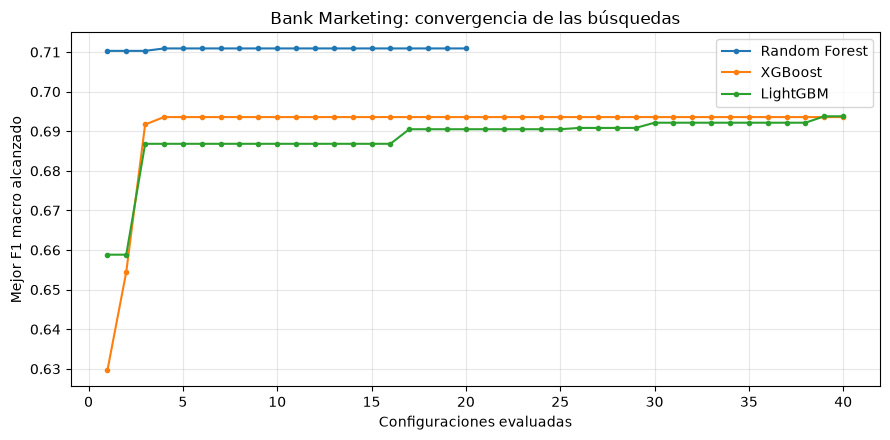

Configuraciones  Mejor F1 macro
Modelo        Pesos                                              
Random Forest None                              4          0.6659
              balanced                          7          0.7010
              balanced_subsample                9          0.7109
XGBoost       None                             22          0.6692
              balanced                         18          0.6936
LightGBM      None                             17          0.6704
              balanced                         23          0.6938

In [44]:
fig, ax = plt.subplots(figsize=(9, 4.5))
for nombre, b in BUSQUEDAS_BANCO.items():
    f1 = b.cv_results_["mean_test_score"]
    ax.plot(np.arange(1, len(f1) + 1), np.maximum.accumulate(f1), marker=".", label=nombre)
ax.set_xlabel("Configuraciones evaluadas")
ax.set_ylabel("Mejor F1 macro alcanzado")
ax.set_title("Bank Marketing: convergencia de las búsquedas")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Mejor resultado con y sin pesos por clase en cada búsqueda
filas = []
for nombre, b in BUSQUEDAS_BANCO.items():
    r = pd.DataFrame(b.cv_results_)
    r["pesos"] = [str(p["modelo__class_weight"]) for p in r["params"]]
    for pesos, g in r.groupby("pesos"):
        filas.append({"Modelo": nombre, "Pesos": pesos, "Configuraciones": len(g),
                      "Mejor F1 macro": g["mean_test_score"].max()})
display(pd.DataFrame(filas).set_index(["Modelo", "Pesos"]).round(4))

In [45]:
for nombre in ["Random Forest", "XGBoost", "LightGBM"]:
    b = BUSQUEDAS_BANCO[nombre]
    evaluar_banco(nombre, b.best_estimator_, resumir(b.best_params_))

Random Forest: F1 macro = 0.7109 ± 0.0041 | sensibilidad = 0.601 | tiempo de entrenamiento = 20.35 s


XGBoost: F1 macro = 0.6936 ± 0.0032 | sensibilidad = 0.578 | tiempo de entrenamiento = 1.45 s


LightGBM: F1 macro = 0.6938 ± 0.0027 | sensibilidad = 0.631 | tiempo de entrenamiento = 0.93 s


Ahora combinamos los mejores modelos con votación suave y *stacking*, como en la Parte 1. En este caso combinamos la regresión logística balanceada, *Random Forest*, XGBoost y LightGBM, ya que son los modelos que mejor funcionaron en este conjunto.

Hay dos diferencias con la Parte 1. La primera es que al meta-modelo le pusimos pesos balanceados por clase, igual que a los demás modelos de esta parte. La segunda es que el *stacking* entrena a los modelos base con una validación cruzada interna para generar las probabilidades con las que aprende el meta-modelo, y por defecto esa validación interna **no revuelve** a los clientes. Como vimos en la fase 9, el archivo está ordenado por fecha, entonces cada parte interna correspondería a un periodo distinto y el meta-modelo aprendería con probabilidades que no se parecen a las de los demás periodos. En una primera prueba con `cv=5` el *stacking* obtuvo un F1 macro de 0.37, incluso menor que el clasificador que siempre responde "no". Por eso en la validación interna usamos pliegues estratificados y revueltos (`CV_INTERNO`).

In [46]:
mejores_banco = [("lr", lr_banco_pesos),
                 ("rf", BUSQUEDAS_BANCO["Random Forest"].best_estimator_),
                 ("xgb", BUSQUEDAS_BANCO["XGBoost"].best_estimator_),
                 ("lgbm", BUSQUEDAS_BANCO["LightGBM"].best_estimator_)]

evaluar_banco("Votación suave", VotingClassifier(mejores_banco, voting="soft"),
              "LR balanceada + RF + XGBoost + LightGBM")
CV_INTERNO = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

meta_balanceado = LogisticRegression(max_iter=1000, class_weight="balanced")
evaluar_banco("Stacking", StackingClassifier(mejores_banco, final_estimator=meta_balanceado,
                                             cv=CV_INTERNO),
              "LR balanceada + RF + XGBoost + LightGBM, meta-modelo logístico balanceado")

Votación suave: F1 macro = 0.7059 ± 0.0039 | sensibilidad = 0.612 | tiempo de entrenamiento = 21.29 s


Stacking: F1 macro = 0.6821 ± 0.0047 | sensibilidad = 0.645 | tiempo de entrenamiento = 103.70 s


Por último, en la Tarea 4 vimos que el umbral de 0.5 no siempre es el más adecuado cuando las clases están desbalanceadas. Por eso probamos ajustar el umbral de los dos mejores modelos individuales (*Random Forest* y LightGBM) con `TunedThresholdClassifierCV`, que busca el umbral que maximiza el F1 macro usando validación cruzada interna. Como el umbral se ajusta con datos, queda dentro del modelo y en cada pliegue se elige solo con los clientes de entrenamiento. Por la misma razón que en el *stacking*, la validación interna usa los pliegues revueltos `CV_INTERNO`.

In [47]:
from sklearn.model_selection import TunedThresholdClassifierCV

for nombre in ["Random Forest", "LightGBM"]:
    b = BUSQUEDAS_BANCO[nombre]
    con_umbral = TunedThresholdClassifierCV(b.best_estimator_, scoring="f1_macro", cv=CV_INTERNO)
    evaluar_banco(f"{nombre} + umbral ajustado", con_umbral,
                  resumir(b.best_params_) + ", umbral ajustado por F1 macro")

Random Forest + umbral ajustado: F1 macro = 0.7167 ± 0.0063 | sensibilidad = 0.543 | tiempo de entrenamiento = 85.03 s


LightGBM + umbral ajustado: F1 macro = 0.7192 ± 0.0076 | sensibilidad = 0.544 | tiempo de entrenamiento = 5.88 s


Para saber qué umbral se elige, ajustamos los dos modelos con todos los clientes y mostramos el umbral encontrado.

In [48]:
for nombre in ["Random Forest", "LightGBM"]:
    con_umbral = TunedThresholdClassifierCV(BUSQUEDAS_BANCO[nombre].best_estimator_,
                                            scoring="f1_macro", cv=CV_INTERNO, n_jobs=-1).fit(Xb, yb)
    print(f"{nombre}: umbral elegido = {con_umbral.best_threshold_:.3f}")

Random Forest: umbral elegido = 0.583


LightGBM: umbral elegido = 0.676


### Resultados de la búsqueda

*AdaBoost* con 400 tocones obtuvo 0.6321, por debajo de la regresión logística de la Tarea 4 y con una sensibilidad de `yes` de apenas 0.207. Igual que en la deserción, *AdaBoost* sin pesos por clase se inclina hacia la clase mayoritaria.

El mejor modelo individual fue *Random Forest*, con un F1 macro de 0.7109 ± 0.0041, con 200 árboles, `max_features` ≈ 0.78, al menos 12 clientes por hoja, profundidad máxima de 30, criterio de entropía y pesos `"balanced_subsample"`. XGBoost (0.6936) y LightGBM (0.6938) quedaron prácticamente empatados entre sí y por debajo de *Random Forest*. Esto es diferente a lo que pasó en la deserción, donde el *boosting* quedó por encima de *Random Forest*.

En la gráfica de convergencia se observa que las tres búsquedas llegaron a una meseta. *Random Forest* casi no mejora después de la primera configuración y XGBoost deja de mejorar a partir de la configuración 4. LightGBM sigue mejorando en milésimas hasta la configuración 39, pero esas mejoras son menores a 0.003, que es del orden de su desviación estándar entre pliegues.

En la tabla de pesos por clase se confirma lo que vimos en la deserción: en los tres modelos la mejor configuración con pesos supera a la mejor sin pesos por entre 0.024 y 0.045. Este es el hiperparámetro que más influye en este conjunto.

Al combinar modelos no se mejoró al mejor modelo individual. La votación suave (0.7059) queda un poco por debajo de *Random Forest*, y el *stacking* (0.6821) queda incluso por debajo de XGBoost y LightGBM por separado, además de ser el modelo más lento (más de un minuto y medio por pliegue en nuestra ejecución).

Lo que sí ayudó fue ajustar el umbral. Con el umbral ajustado *Random Forest* sube de 0.7109 a 0.7167 y LightGBM de 0.6938 a 0.7192. En los dos casos el umbral elegido es mayor a 0.5 (0.583 para *Random Forest* y 0.676 para LightGBM). Esto tiene sentido, ya que con los pesos balanceados los modelos le dan más importancia a los clientes que aceptan y sus probabilidades de `yes` quedan más altas de lo normal, entonces con un umbral de 0.5 predicen "yes" para demasiados clientes. Al subir el umbral la sensibilidad de `yes` baja (de 0.631 a 0.544 en LightGBM), pero se reducen las llamadas a clientes que no aceptan y el F1 macro mejora.

## 12. Comparación de los modelos de *Bank Marketing*

Presentamos la tabla con todos los modelos probados, ordenados por F1 macro, con la sensibilidad de la clase `yes` y el tiempo promedio de entrenamiento en un pliegue.

In [49]:
comparacion_banco = construir_tabla(TABLA_BANCO, "Sensibilidad yes")
display(comparacion_banco)

,F1 macro (media ± desv.),Sensibilidad yes,Tiempo de entrenamiento (s),Configuración
Modelo,,,,
LightGBM + umbral ajustado,0.7192 ± 0.0076,0.544,5.88,"class_weight=balanced, colsample_bytree=0.861, learning_rate=0.026, min_child_samples=39, n_estimators=291, num_leaves=52, reg_lambda=0.126, subsample=0.997, umbral ajustado por F1 macro"
Random Forest + umbral ajustado,0.7167 ± 0.0063,0.543,85.03,"class_weight=balanced_subsample, criterion=entropy, max_depth=30, max_features=0.777, min_samples_leaf=12, umbral ajustado por F1 macro"
Random Forest,0.7109 ± 0.0041,0.601,20.35,"class_weight=balanced_subsample, criterion=entropy, max_depth=30, max_features=0.777, min_samples_leaf=12"
Votación suave,0.7059 ± 0.0039,0.612,21.29,LR balanceada + RF + XGBoost + LightGBM
LightGBM,0.6938 ± 0.0027,0.631,0.93,"class_weight=balanced, colsample_bytree=0.861, learning_rate=0.026, min_child_samples=39, n_estimators=291, num_leaves=52, reg_lambda=0.126, subsample=0.997"
XGBoost,0.6936 ± 0.0032,0.578,1.45,"class_weight=balanced, colsample_bytree=0.512, learning_rate=0.0596, max_depth=8, n_estimators=269, reg_lambda=0.128, subsample=0.987"
XGBoost (configuración de deserción),0.6861 ± 0.0039,0.642,0.80,"class_weight=balanced, colsample_bytree=0.949, learning_rate=0.0787, max_depth=4, n_estimators=211, reg_lambda=0.171, subsample=0.832"
Stacking,0.6821 ± 0.0047,0.645,103.70,"LR balanceada + RF + XGBoost + LightGBM, meta-modelo logístico balanceado"
Regresión logística balanceada,0.6739 ± 0.0040,0.629,0.43,class_weight=balanced


Mostramos la matriz de confusión del mejor modelo, con predicciones de validación cruzada sobre los mismos pliegues.

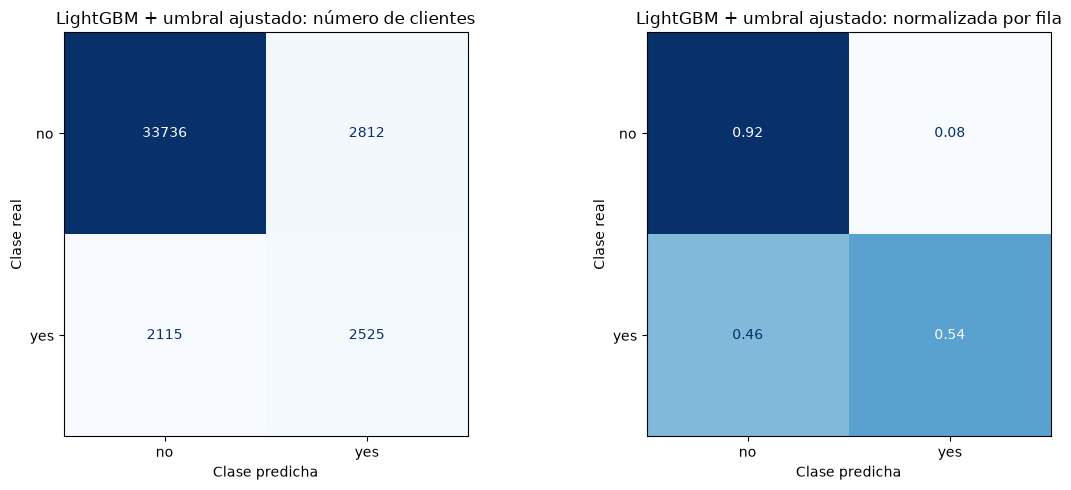

In [50]:
MEJOR_BANCO = comparacion_banco.index[0]
pred_banco = cross_val_predict(MODELOS_BANCO[MEJOR_BANCO], Xb, yb, cv=CV_BANCO, n_jobs=-1)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay.from_predictions(yb, pred_banco, display_labels=["no", "yes"], ax=ax[0],
                                        cmap="Blues", colorbar=False)
ax[0].set_title(f"{MEJOR_BANCO}: número de clientes")
ConfusionMatrixDisplay.from_predictions(yb, pred_banco, display_labels=["no", "yes"], ax=ax[1],
                                        cmap="Blues", colorbar=False, normalize="true",
                                        values_format=".2f")
ax[1].set_title(f"{MEJOR_BANCO}: normalizada por fila")
for a in ax:
    a.set_xlabel("Clase predicha")
    a.set_ylabel("Clase real")
plt.tight_layout()
plt.show()

### Resultados de la comparación: ¿funcionó lo mismo que en la deserción, y por qué?

El mejor modelo para *Bank Marketing* es LightGBM con el umbral ajustado, con un F1 macro de 0.7192 ± 0.0076, seguido de *Random Forest* con el umbral ajustado (0.7167) y *Random Forest* sin ajustar el umbral (0.7109). La diferencia entre los dos primeros es de 0.0025, que es menor que su desviación estándar, entonces los dos son igual de buenos, pero LightGBM tarda más de diez veces menos en entrenarse por pliegue.

En la matriz de confusión se observa que el modelo detecta al 54 % de los clientes que aceptan (2525 de 4640) y solo marca como "yes" al 8 % de los clientes que no aceptan (2812 de 36,548). De los 5337 clientes que el modelo recomienda llamar, 2525 aceptan, es decir, aproximadamente uno de cada dos. Comparado con la regresión logística de la Tarea 4, que con el umbral de 0.5 solo detectaba al 22 % de los clientes que aceptan, el banco encontraría a más del doble de clientes interesados.

¿Funcionó lo mismo que en la deserción? **En parte sí y en parte no.**

- **Lo que sí funcionó igual:** los pesos por clase fueron la decisión más importante en los dos conjuntos, y los modelos sin pesos (*AdaBoost*, la regresión logística de la Tarea 4) quedaron en la parte baja de la tabla. Además, el *boosting* optimizado volvió a estar entre los mejores modelos, y el *stacking* volvió a ser de los modelos más lentos sin mejorar a los modelos individuales.
- **Lo que no funcionó igual:** en la deserción los ensambles casi no ganaron sobre los clasificadores base (la mejor ganancia fue de 0.011 sobre el SVM, dentro de la desviación estándar), mientras que en *Bank Marketing* los ensambles de árboles sí ganaron claramente sobre la regresión logística balanceada: *Random Forest* la supera por 0.037 y LightGBM con umbral por 0.045, diferencias de varias veces la desviación estándar. También el orden cambió: en la deserción el *boosting* le ganó a *Random Forest*, y aquí *Random Forest* le ganó al *boosting* hasta que se ajustó el umbral.

¿Por qué? Creemos que se debe a las características de los dos conjuntos:

1. **Tamaño.** *Bank Marketing* tiene 41,188 clientes contra 3539 estudiantes. Con más datos los modelos más complejos, como los ensambles de árboles, pueden aprender patrones más detallados sin ajustarse demasiado. Además, la desviación estándar entre pliegues es mucho menor (alrededor de 0.004 contra 0.010–0.018 en la deserción), por lo que las diferencias entre modelos se pueden distinguir mejor.
2. **Tipo de relación entre atributos y clase.** En la deserción la información más útil son las unidades aprobadas y las calificaciones del primer semestre, y su relación con la clase es bastante directa (a menos unidades aprobadas, más probabilidad de desertar), por eso un modelo lineal como la regresión logística ya captura casi todo. En *Bank Marketing* la respuesta depende de combinaciones entre atributos, por ejemplo del mes, el tipo de contacto, si el cliente fue contactado antes (`pdays` = 999 significa que no) y los indicadores económicos, que cambian mucho con el tiempo, como vimos en la fase 9. Los árboles pueden representar estas combinaciones con sus cortes, mientras que la regresión logística no.
3. **Número de clases y umbral.** La deserción tiene tres clases y *Bank Marketing* solo dos, con un desbalance mayor (11 % contra 18 % de la clase minoritaria). En un problema de dos clases el umbral es una sola decisión muy fácil de ajustar, y como vimos en la Tarea 4, con clases desbalanceadas el umbral de 0.5 no es el más adecuado.

## 13. Modelo final

Entrenamos el mejor modelo con los 41,188 clientes y lo guardamos con `joblib` en el archivo que se entrega. Después lo cargamos de nuevo para verificar que el archivo funciona y que el modelo puede predecir directamente a partir de las columnas originales (sin `duration` ni `y`), ya que todo el preprocesamiento está dentro del modelo.

In [51]:
ARCHIVO_MODELO = "cesar-jardines_modelo.joblib"

modelo_final = clone(MODELOS_BANCO[MEJOR_BANCO])
inicio = time.perf_counter()
modelo_final.fit(Xb, yb)
print(f"Modelo final: {MEJOR_BANCO}")
print(f"Configuración: {TABLA_BANCO[MEJOR_BANCO]['Configuración']}")
print(f"Tiempo de entrenamiento con todos los clientes: {time.perf_counter() - inicio:.1f} s")

joblib.dump(modelo_final, ARCHIVO_MODELO)

# Verificamos que el archivo guardado predice igual que el modelo en memoria
modelo_cargado = joblib.load(ARCHIVO_MODELO)
pred_cargado = modelo_cargado.predict(Xb)
print("¿Mismas predicciones que el modelo en memoria?", np.array_equal(pred_cargado, modelo_final.predict(Xb)))
print("Clientes predichos como 'yes':", pred_cargado.sum(), "de", len(pred_cargado))

Modelo final: LightGBM + umbral ajustado
Configuración: class_weight=balanced, colsample_bytree=0.861, learning_rate=0.026, min_child_samples=39, n_estimators=291, num_leaves=52, reg_lambda=0.126, subsample=0.997, umbral ajustado por F1 macro
Tiempo de entrenamiento con todos los clientes: 5.5 s


¿Mismas predicciones que el modelo en memoria? True
Clientes predichos como 'yes': 5641 de 41188


### Resultado del modelo final

El modelo final es LightGBM con pesos balanceados y el umbral ajustado, entrenado con los 41,188 clientes. Se guardó en el archivo `cesar-jardines_modelo.joblib`, y al cargarlo de nuevo produce exactamente las mismas predicciones que el modelo en memoria. Como el preprocesamiento y el umbral están dentro del modelo, para usarlo basta con pasarle las columnas originales del archivo sin `duration` ni `y`.

## 14. Conclusiones

En esta práctica revisamos qué aportan las tres familias de ensambles en dos problemas distintos.

***Bagging*.** En la deserción vimos que *bagging* reduce la varianza: un árbol sin límite memoriza el entrenamiento (F1 de 1.0 en entrenamiento y 0.58 en validación) y al promediar 400 de esos árboles el F1 macro sube a 0.665. Sin embargo, *bagging* sin pesos por clase pierde a la clase minoritaria. Con *Random Forest* y pesos balanceados se llegó a 0.682 en la deserción, empatado con el SVM, mientras que en *Bank Marketing* *Random Forest* fue el mejor modelo individual (0.711), claramente por encima de la regresión logística.

***Boosting*.** Con *AdaBoost* vimos que el *boosting* reduce el sesgo: un tocón no puede ni siquiera predecir las tres clases, y al sumar 400 tocones el F1 sube tanto en entrenamiento como en validación. XGBoost y LightGBM fueron los mejores modelos de la deserción (0.693) y, con el umbral ajustado, LightGBM fue el mejor de *Bank Marketing* (0.719). Además fueron de los modelos más rápidos de entrenar y de optimizar.

**Votación y *stacking*.** En la deserción los errores de los cinco clasificadores base están muy correlacionados (el 11 % de los estudiantes es clasificado mal por los cinco), por lo que combinarlos casi no ayuda: solo la votación dura mejoró un poco al SVM, y la votación suave y el *stacking* quedaron por debajo. En *Bank Marketing* tampoco superaron al mejor modelo individual. En los dos conjuntos el *stacking* fue de los modelos más lentos.

**Diferencias entre los dos problemas.** La principal diferencia es cuánto ganan los ensambles. En la deserción, con pocos estudiantes y una relación bastante directa entre las calificaciones del primer semestre y la clase, los clasificadores base bien ajustados ya estaban cerca del límite de lo que se puede predecir, y los ensambles ganan menos que la variación entre pliegues. En *Bank Marketing*, con muchos más clientes, atributos categóricos y una relación que depende de combinaciones entre el mes, el contacto y la situación económica, los ensambles de árboles sí ganaron claramente sobre el modelo lineal.

Por último, hay dos cosas que vale la pena resaltar. La primera es que en los dos conjuntos la decisión que más influyó en el F1 macro fue usar pesos por clase, más que la elección del ensamble. La segunda es que es importante revisar cómo están ordenados los datos: en *Bank Marketing* el archivo está ordenado por fecha, y al usar pliegues internos sin revolver el *stacking* y el ajuste del umbral dieron resultados peores que el clasificador que siempre responde "no". Este error no se veía en el código, solo en los resultados.

## Declaración de uso de inteligencia artificial

Se utilizó un modelo de inteligencia artificial (Anthropic, Claude Opus 5.5) como asistente para repasar los conceptos de ensambles (*bagging*, *boosting*, votación y *stacking*), organizar la estructura del notebook con base en la Práctica 3 y la Tarea 4, proponer y depurar el código, proponer borradores de las lecturas de resultados y de las conclusiones, y revisar la ortografía y el formato Markdown. Los borradores fueron revisados y reescritos por mí.

Todas las celdas fueron ejecutadas y sus resultados verificados por mí, quien se hace responsable del contenido final.